# PC-QAOA and PenaltyQAOA Comparison

This notebook reads the fixed COP manifest and saved results. It does not generate COPs or run optimization.

Mean plots show pointwise 95% Student-$t$ confidence intervals across COPs:

$$\bar y \pm t_{0.975,n-1}\frac{s}{\sqrt{n}}.$$

Here, $n$ is the number of COPs and $s$ is their sample standard deviation. Optimizer restarts and measurement shots are not independent observations. Paired comparisons use the per-COP difference between PC-QAOA and PenaltyQAOA. Intervals are omitted when fewer than two COPs contribute.

In [1]:
from pathlib import Path
from collections import Counter
import json, os, shutil, subprocess, warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display, Image
from scipy.stats import t

candidates = [Path.cwd(), *Path.cwd().parents, Path.cwd() / "code-tuning"]
REPO = next(path for path in candidates if (path / "final_experiment/config.json").exists())
os.environ.setdefault("MPLCONFIGDIR", str(REPO / "final_experiment/.cache/matplotlib"))

MANIFEST_PATH = Path(os.environ.get(
    "PCQAOA_FINAL_MANIFEST", REPO / "final_experiment/artifacts/manifest.json"))
PC_DIR = Path(os.environ.get(
    "PCQAOA_FINAL_PC_RESULTS", REPO / "final_experiment/results/pcqaoa"))
PENALTY_DIR = Path(os.environ.get(
    "PCQAOA_FINAL_PENALTY_RESULTS", REPO / "final_experiment/results/penaltyqaoa"))
if not (PC_DIR / "run.json").exists():
    PC_DIR = REPO / "final_experiment/results/smoke_pcqaoa"
if not (PENALTY_DIR / "run.json").exists():
    PENALTY_DIR = REPO / "final_experiment/results/smoke_penaltyqaoa"
FIGURE_DIR = Path(os.environ.get(
    "PCQAOA_FINAL_FIGURES", REPO / "final_experiment/results/figures"))
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

COLORS = {"PC-QAOA": "#9063cd", "PenaltyQAOA": "#3e8fb0",
          "Disjoint": "#31748f", "Overlapping": "#eb6f92",
          "Teal": "#31748f", "Gold": "#f6c177", "Gray": "#6e6a86"}
MARKERS = {"PC-QAOA": "o", "PenaltyQAOA": "s"}

mpl.rcParams.update({
    "font.family": "serif", "font.serif": ["DejaVu Serif"],
    "mathtext.fontset": "cm", "font.size": 11, "axes.titlesize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.22, "grid.linewidth": 0.5,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "savefig.dpi": 300, "pdf.fonttype": 42,
    "pgf.texsystem": "pdflatex", "pgf.rcfonts": False, "text.usetex": False,
})

class FigureWriter:
    def __init__(self, directory, latex=True):
        self.directory = Path(directory)
        self.directory.mkdir(parents=True, exist_ok=True)
        self.latex = latex and bool(shutil.which("pdflatex"))
        self.font_status = ("LaTeX Computer Modern (PGF)" if self.latex else
                            "Matplotlib Computer Modern Math / DejaVu Serif")

    def save(self, figure, name):
        pdf = self.directory / f"{name}.pdf"
        png = self.directory / f"{name}.png"
        figure.tight_layout()
        if self.latex:
            try:
                figure.savefig(pdf, backend="pgf", bbox_inches="tight")
                if shutil.which("pdftocairo"):
                    subprocess.run(["pdftocairo", "-png", "-singlefile", "-r", "300",
                                    str(pdf), str(png.with_suffix(""))],
                                   check=True, capture_output=True)
                else:
                    figure.savefig(png, backend="pgf", bbox_inches="tight")
            except Exception as error:
                self.latex = False
                self.font_status = "Matplotlib Computer Modern Math / DejaVu Serif (LaTeX Failed)"
                warnings.warn(f"LaTeX rendering failed; using Matplotlib fonts: {error}")
        if not self.latex:
            figure.savefig(pdf, bbox_inches="tight")
            figure.savefig(png, bbox_inches="tight")
        (self.directory / "font_status.json").write_text(
            json.dumps({"font": self.font_status}, indent=2) + "\n")
        plt.close(figure)
        display(Image(filename=str(png), width=900))
        return png

writer = FigureWriter(FIGURE_DIR, latex=True)
print("Manifest:", MANIFEST_PATH)
print("PC-QAOA Results:", PC_DIR)
print("PenaltyQAOA Results:", PENALTY_DIR)

Manifest: /home/ard22l/PCQAOA/code-tuning/final_experiment/artifacts/manifest.json
PC-QAOA Results: /home/ard22l/PCQAOA/code-tuning/final_experiment/results/pcqaoa
PenaltyQAOA Results: /home/ard22l/PCQAOA/code-tuning/final_experiment/results/penaltyqaoa


## Data Loading and Completion

The manifest defines the 500 COPs shared by both methods. Result files are joined by `instance_id`. A paired comparison includes a COP only when both methods have saved the required result.

In [2]:
def load_json(path, default=None):
    path = Path(path)
    return json.loads(path.read_text()) if path.exists() else default

def distribution_metrics(distribution, reference):
    distribution = np.asarray(distribution, dtype=float)
    total = distribution.sum()
    if total <= 0:
        return {"ar_feas": np.nan}
    distribution = distribution / total
    feasible = np.asarray(reference["feasible_mask"], dtype=bool)
    values = np.asarray(reference["objective_values"], dtype=float)
    p_feasible = float(distribution[feasible].sum())
    if p_feasible <= 0:
        return {"ar_feas": 0.0}
    feasible_objective = float(np.dot(distribution[feasible], values[feasible]) / p_feasible)
    denominator = float(reference["f_max_feasible"] - reference["f_star"])
    ar_feas = ((float(reference["f_max_feasible"]) - feasible_objective) / denominator
               if abs(denominator) > 1e-12 else np.nan)
    return {"ar_feas": ar_feas}

def load_results(directory, method, references):
    rows, depths = [], []
    directory = Path(directory)
    for path in sorted(directory.glob("final_*/result.json")):
        rows.append(load_json(path))
    for path in sorted(directory.glob("final_*/depths.json")):
        instance_id = path.parent.name
        reference = references[instance_id]
        metadata = {
            "n_x": reference["n_x"], "support": reference["support"],
            "regime": reference["regime"], "m": reference["m"], "o": reference["o"],
            "feasible_fraction": reference["feasible_fraction"], "delta": reference["delta"],
            "manuscript_delta": 5 + 2 * abs(reference["f_min_unconstrained"]),
        }
        for row in load_json(path, []):
            sampled = distribution_metrics(row["counts"], reference)
            exact = distribution_metrics(row["probabilities"], reference)
            derived = {**sampled, **{f"exact_{key}": value for key, value in exact.items()}}
            depths.append({
                "instance_id": instance_id, "method": method, **metadata, **derived,
                **{key: value for key, value in row.items()
                   if key not in ["angles", "history", "restarts", "counts", "probabilities"]},
            })
    return pd.DataFrame(rows), pd.DataFrame(depths)

def completion(directory, expected=None):
    statuses = Counter()
    directory = Path(directory)
    selection = load_json(directory / "selection.json")
    if expected is None:
        expected = len(selection["instance_ids"]) if selection else 500
    for path in directory.glob("final_*/status.json"):
        statuses[load_json(path)["status"]] += 1
    completed = len(list(directory.glob("final_*/result.json")))
    statuses["pending"] = max(0, expected - sum(statuses.values()))
    return {"expected": expected, "completed_results": completed,
            "statuses": dict(statuses)}

if not MANIFEST_PATH.exists():
    raise FileNotFoundError(
        f"Missing {MANIFEST_PATH}. Generate or copy the local manifest before using this notebook.")
manifest = load_json(MANIFEST_PATH)
references = {row["id"]: row for row in manifest["instances"]}
instances = pd.DataFrame(manifest["instances"])
instances["manuscript_delta"] = 5 + 2 * instances["f_min_unconstrained"].abs()
pc, pc_depths = load_results(PC_DIR, "PC-QAOA", references)
penalty, penalty_depths = load_results(PENALTY_DIR, "PenaltyQAOA", references)
for frame, label in [(pc, "PC-QAOA"), (penalty, "PenaltyQAOA")]:
    if not frame.empty:
        frame["method_label"] = label
for frame in [pc_depths, penalty_depths]:
    if not frame.empty:
        frame["method_label"] = frame["method"]
results = pd.concat([pc, penalty], ignore_index=True) if len(pc) or len(penalty) else pd.DataFrame()
depths = pd.concat([pc_depths, penalty_depths], ignore_index=True) if len(pc_depths) or len(penalty_depths) else pd.DataFrame()

print("Manifest COPs:", len(instances))
print("PC-QAOA:", json.dumps(completion(PC_DIR), indent=2))
print("PenaltyQAOA:", json.dumps(completion(PENALTY_DIR), indent=2))
display(instances[["id", "vcg_id", "vcg_family", "support", "n_x", "m", "o",
                   "n_structural", "n_penalty", "delta"]].head())

Manifest COPs: 500
PC-QAOA: {
  "expected": 500,
  "completed_results": 83,
  "statuses": {
    "complete": 83,
    "running": 2,
    "pending": 415
  }
}
PenaltyQAOA: {
  "expected": 500,
  "completed_results": 73,
  "statuses": {
    "complete": 73,
    "running": 2,
    "pending": 425
  }
}


,id,vcg_id,vcg_family,support,n_x,m,o,n_structural,n_penalty,delta
0,final_0001,a_4_equality_01,equality,4,6,2,0,2,0,50.0
1,final_0002,a_4_equality_01,equality,4,6,2,0,2,0,58.0
2,final_0003,a_4_equality_01,equality,4,8,3,0,3,0,108.0
3,final_0004,a_4_equality_01,equality,4,6,2,0,2,0,65.0
4,final_0005,a_4_equality_01,equality,4,6,2,0,2,0,56.0


## Dataset Composition

Each COP contains one trained $L_{\mathrm{fid}}$ VCG constraint and one or two exactly structurally enforceable constraints. The objective coefficients are integers from $-5$ through $5$. PenaltyQAOA uses

$$\delta_{\mathrm{range}}=U_Q-L_Q+1,$$

where $L_Q$ and $U_Q$ are the sums of the negative and positive QUBO coefficients, respectively.

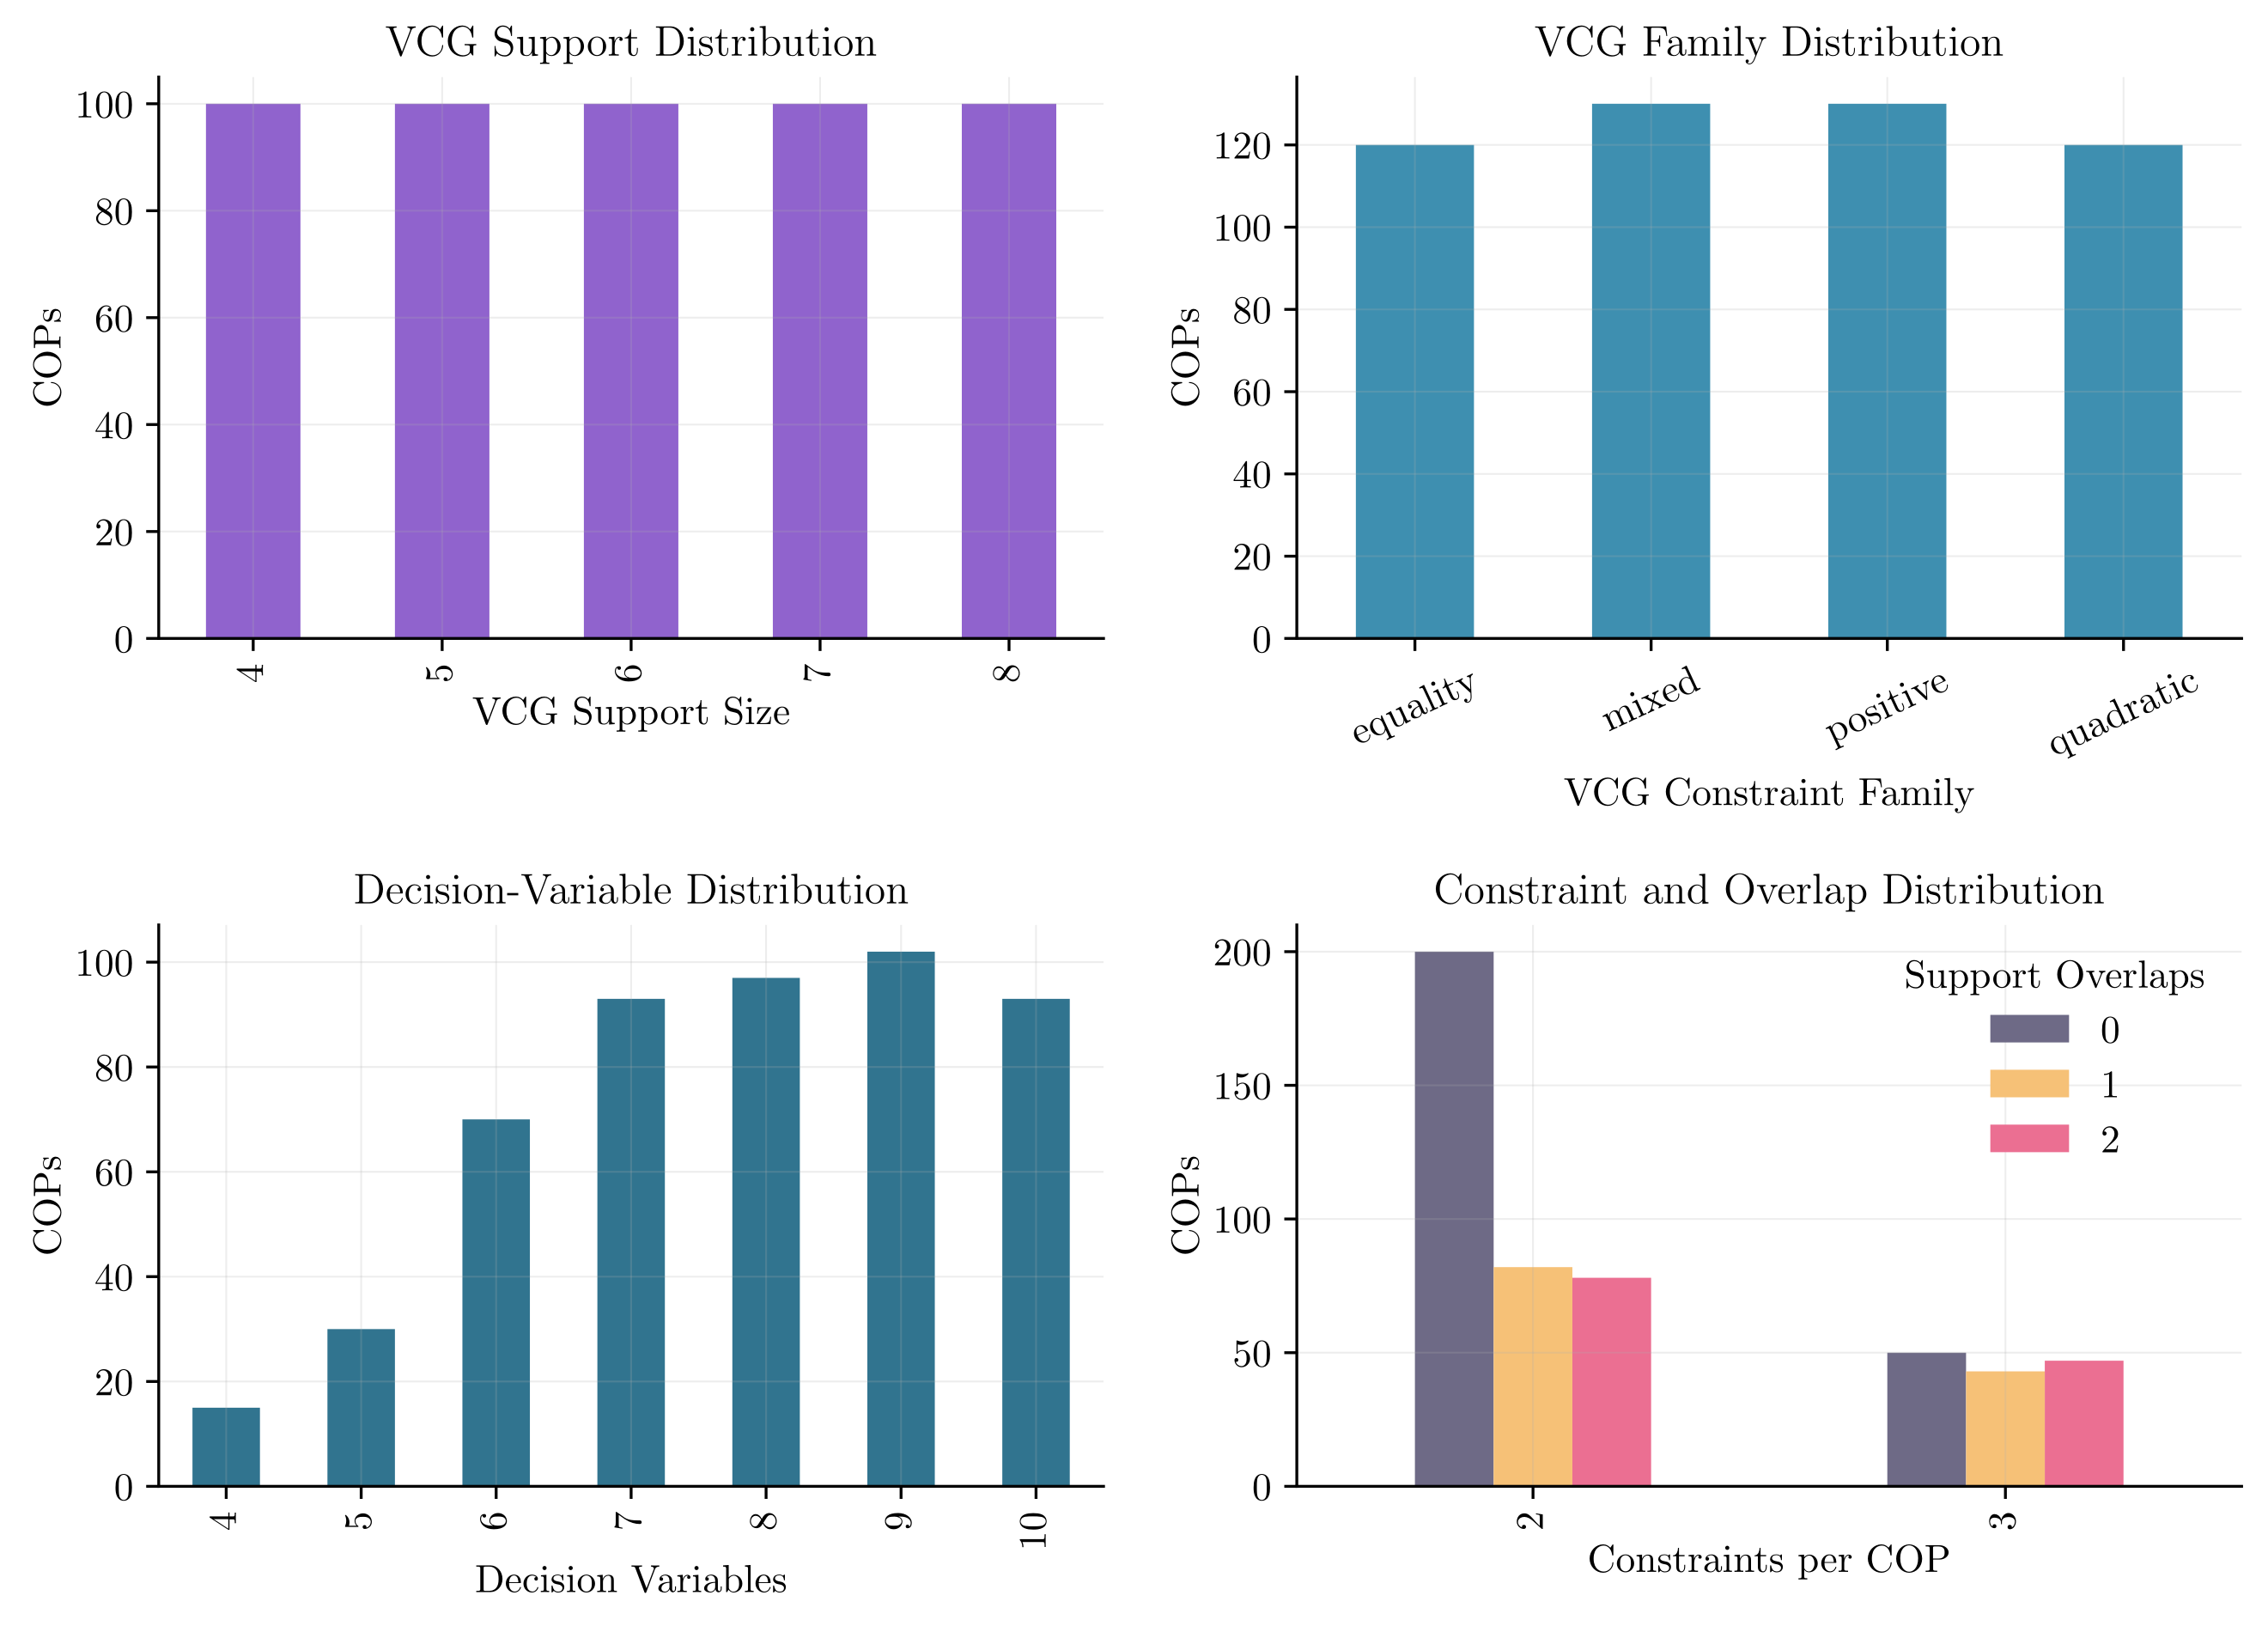

,Occurrences
assignment,128
cardinality_equality,128
cardinality_inequality,128
flow,128
independent_set,128


,Structurally Enforced,Penalized,COPs
0,1,1,160
1,1,2,16
2,2,0,200
3,2,1,74
4,3,0,50


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6.5))
instances["support"].value_counts().sort_index().plot.bar(
    ax=axes[0, 0], color=COLORS["PC-QAOA"])
axes[0, 0].set(xlabel="VCG Support Size", ylabel="COPs", title="VCG Support Distribution")
instances["vcg_family"].value_counts().sort_index().plot.bar(
    ax=axes[0, 1], color=COLORS["PenaltyQAOA"])
axes[0, 1].set(xlabel="VCG Constraint Family", ylabel="COPs", title="VCG Family Distribution")
axes[0, 1].tick_params(axis="x", labelrotation=25)
instances["n_x"].value_counts().sort_index().plot.bar(
    ax=axes[1, 0], color=COLORS["Teal"])
axes[1, 0].set(xlabel="Decision Variables", ylabel="COPs", title="Decision-Variable Distribution")
cell = instances.groupby(["m", "o"]).size().unstack(fill_value=0)
cell.plot.bar(ax=axes[1, 1], color=[COLORS["Gray"], COLORS["Gold"], COLORS["Overlapping"]])
axes[1, 1].set(xlabel="Constraints per COP", ylabel="COPs", title="Constraint and Overlap Distribution")
axes[1, 1].legend(title="Support Overlaps", frameon=False)
writer.save(fig, "dataset_composition")

exact_counts = Counter(category for values in instances["exact_categories"] for category in values)
partitions = instances.groupby(["n_structural", "n_penalty"]).size().rename("COPs").reset_index()
display(pd.Series(exact_counts, name="Occurrences").sort_index().to_frame())
display(partitions.rename(columns={"n_structural": "Structurally Enforced",
                                   "n_penalty": "Penalized"}))

## Optimization Metrics

For the feasible set $\mathcal{F}$ and the set of optimal feasible strings $\mathcal X^\star$,

$$
P(\mathrm{feas})=\sum_{x\in\mathcal{F}}P(x),\qquad
P(\mathrm{opt})=\sum_{x\in\mathcal X^\star}P(x).
$$

Slack registers are marginalized before these decision-level probabilities are calculated. As defined in the manuscript, the feasible-state objective and feasible approximation ratio are

$$
\bar f_{\mathrm{feas}}=
\frac{\sum_{x\in\mathcal{F}}f(x)P(x)}{P(\mathrm{feas})},\qquad
\mathrm{AR}_{\mathrm{feas}}
=\frac{\bar f_{\mathrm{feas}}-f_{\max}^{\mathcal{F}}}
{f_{\min}^{\mathcal{F}}-f_{\max}^{\mathcal{F}}}.
$$

The notebook assigns $\mathrm{AR}_{\mathrm{feas}}=0$ when $P(\mathrm{feas})=0$. Sampled metrics use 10,000 shots. Exact statevector probabilities are saved as diagnostics.

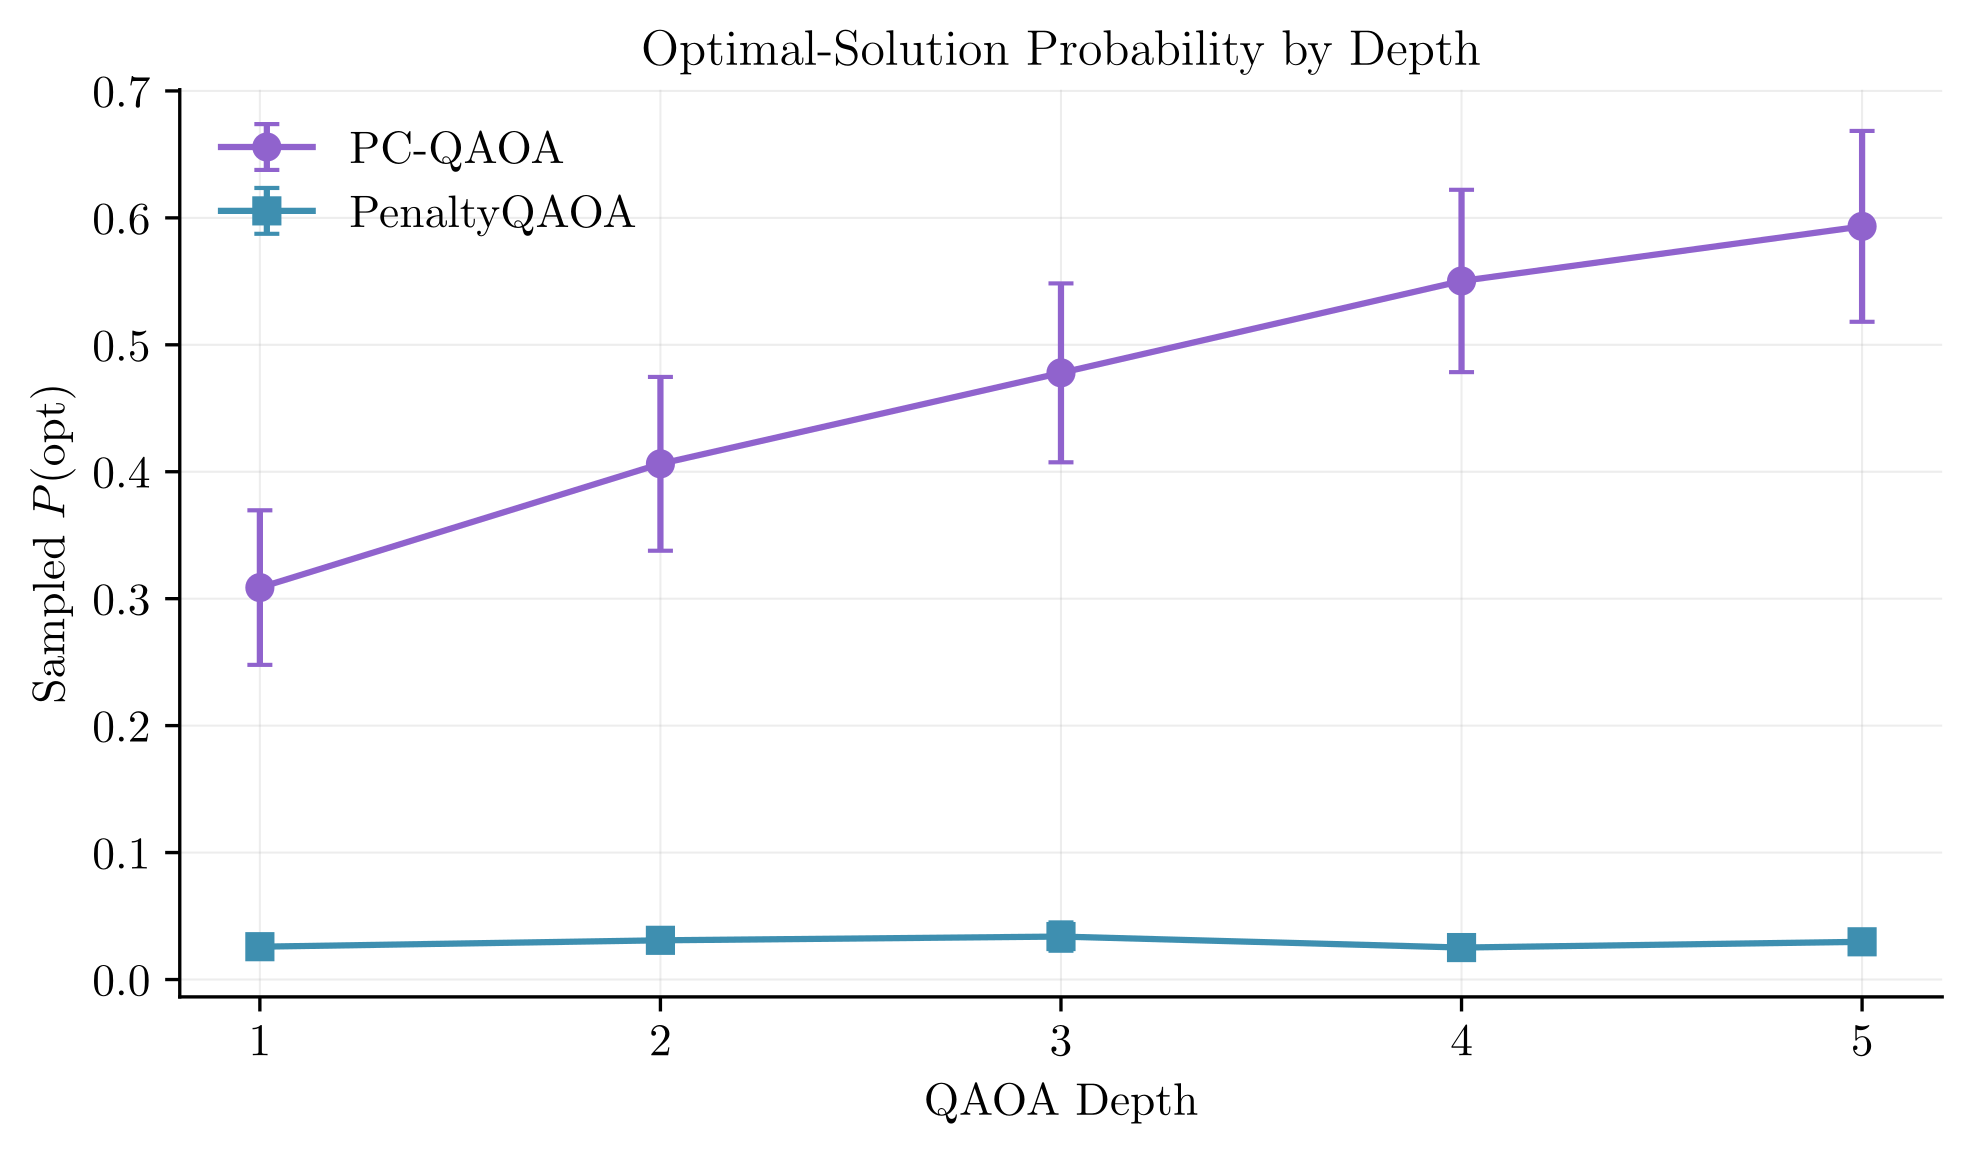

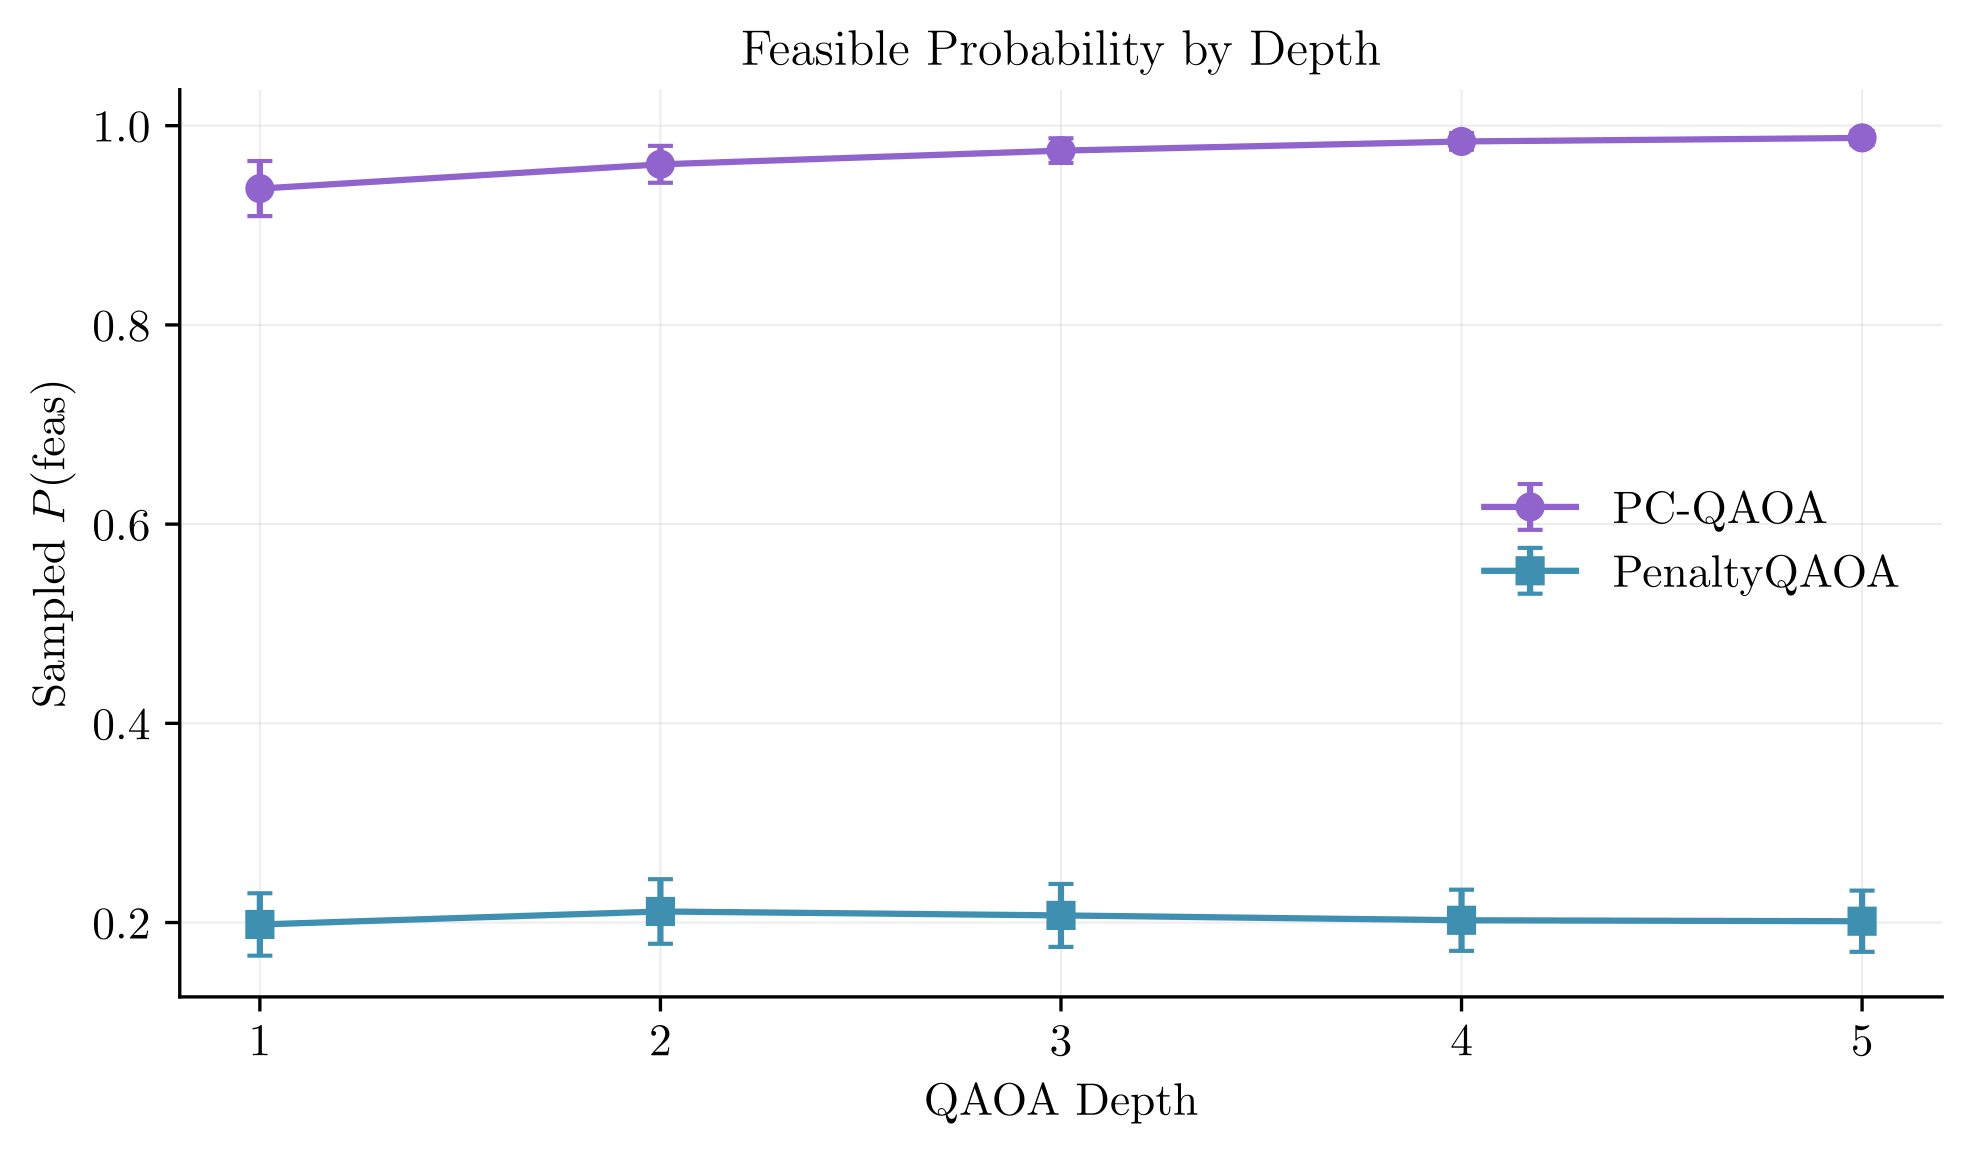

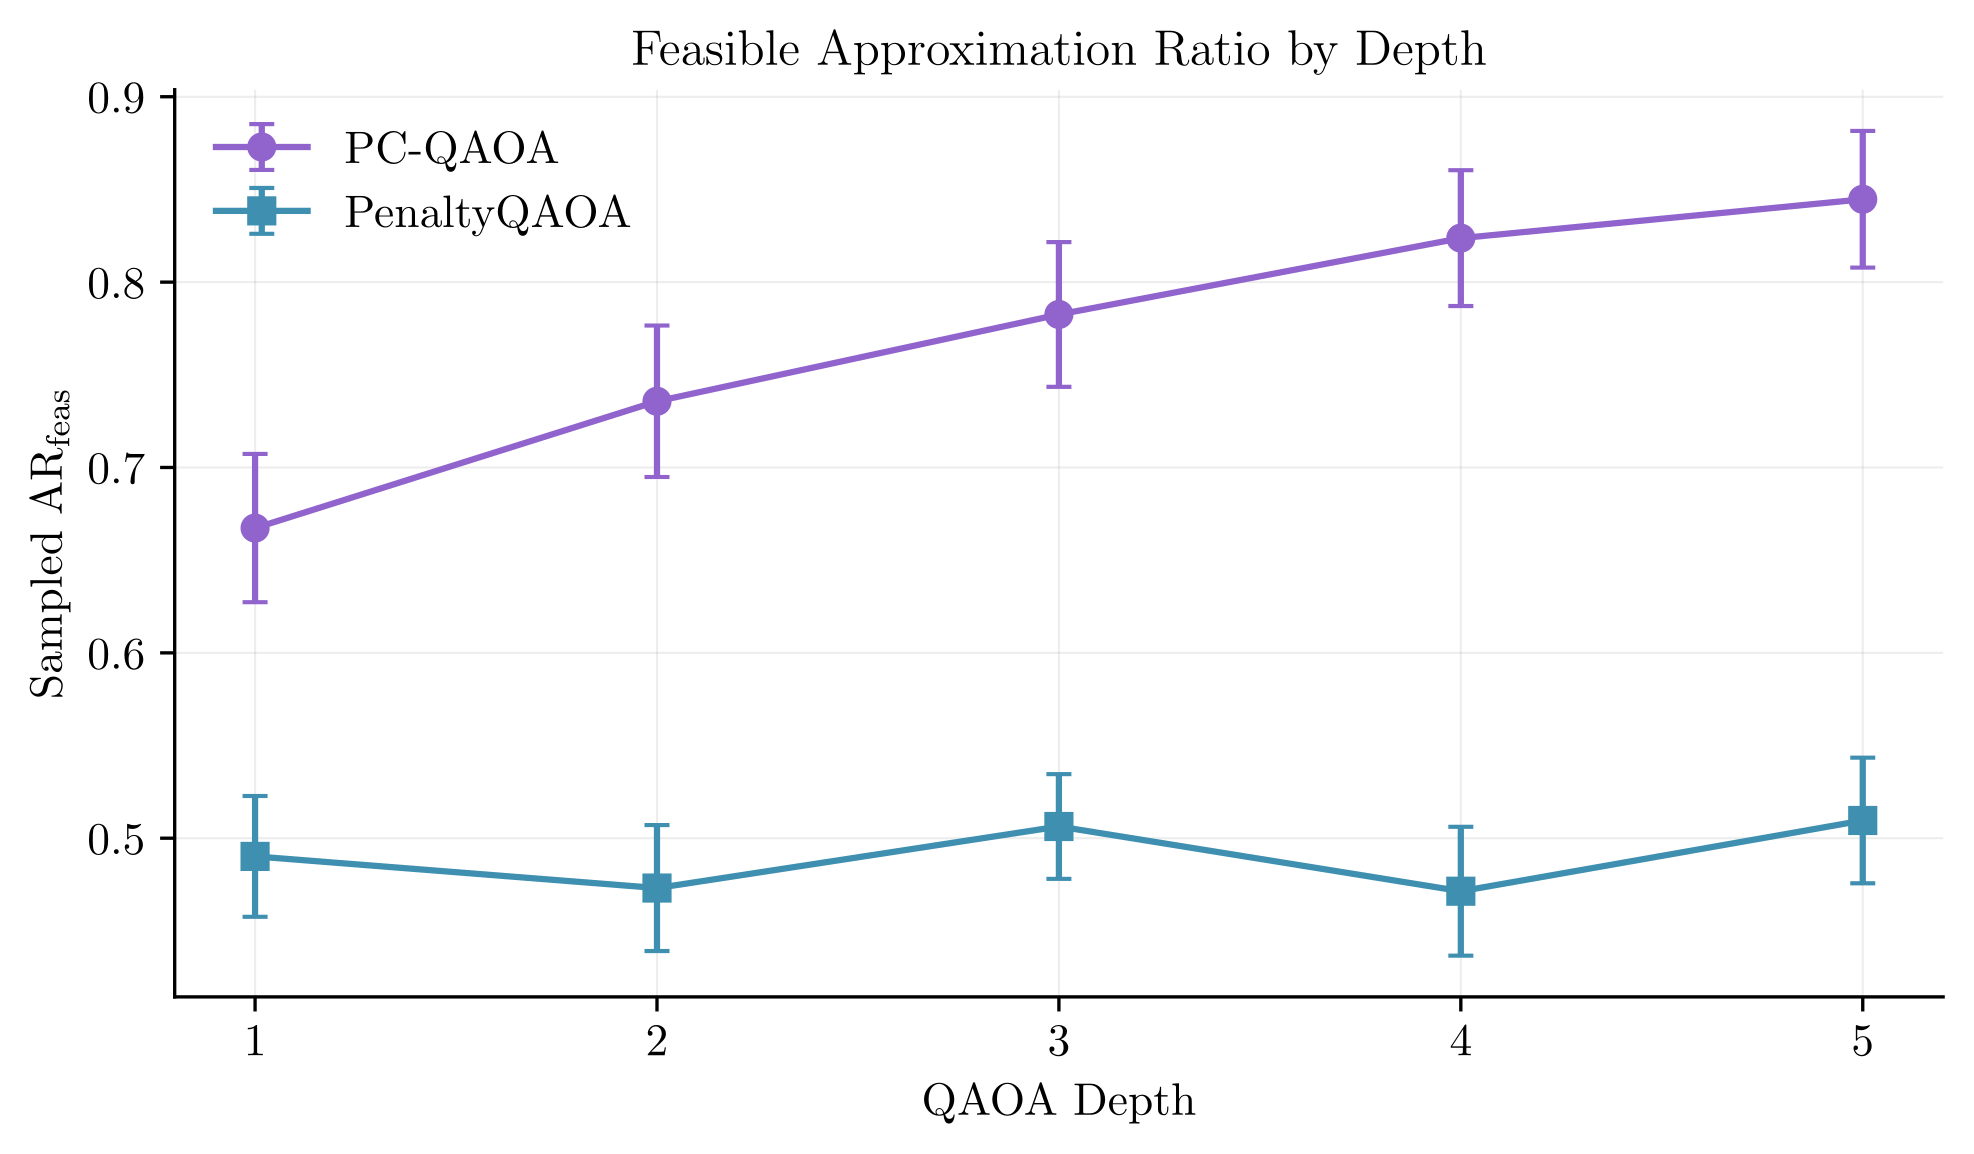

,method_label,depth,mean,std,count,sem,ci95
0,PC-QAOA,1,0.308744,0.282292,85,0.030619,0.060889
1,PC-QAOA,2,0.406229,0.315508,84,0.034425,0.068469
2,PC-QAOA,3,0.477906,0.324710,84,0.035429,0.070466
3,PC-QAOA,4,0.550277,0.330945,84,0.036109,0.071819
4,PC-QAOA,5,0.593288,0.344297,83,0.037791,0.075179
5,PenaltyQAOA,1,0.025848,0.026573,75,0.003068,0.006114
6,PenaltyQAOA,2,0.030874,0.038005,74,0.004418,0.008805
7,PenaltyQAOA,3,0.033838,0.048141,74,0.005596,0.011153
8,PenaltyQAOA,4,0.025164,0.027497,74,0.003196,0.006371
9,PenaltyQAOA,5,0.029707,0.035637,73,0.004171,0.008315


In [4]:
def mean_ci(frame, group, value):
    stats = frame.groupby(group)[value].agg(["mean", "std", "count"])
    stats["sem"] = stats["std"] / np.sqrt(stats["count"])
    stats["ci95"] = t.ppf(0.975, stats["count"] - 1) * stats["sem"]
    stats.loc[stats["count"] < 2, "ci95"] = np.nan
    return stats.reset_index()

def depth_plot(frame, value, ylabel, title, name, reference=None):
    fig, ax = plt.subplots(figsize=(6.8, 4.0))
    for method, subset in frame.groupby("method_label", sort=False):
        stats = mean_ci(subset, "depth", value)
        ax.errorbar(stats["depth"], stats["mean"], yerr=stats["ci95"].fillna(0),
                    color=COLORS[method], marker=MARKERS[method], linewidth=1.5,
                    capsize=3, label=method)
    if reference is not None:
        ax.axhline(reference, color=COLORS["Gray"], linestyle="--", linewidth=1)
    ax.set(xlabel="QAOA Depth", ylabel=ylabel, title=title)
    if len(frame):
        ax.set_xticks(sorted(frame["depth"].unique()))
    ax.legend(frameon=False)
    writer.save(fig, name)

if depths.empty:
    print("No saved depth results are available.")
else:
    depth_plot(depths, "p_optimal", r"Sampled $P(\mathrm{opt})$",
               "Optimal-Solution Probability by Depth", "p_optimal_by_depth")
    depth_plot(depths, "p_feasible", r"Sampled $P(\mathrm{feas})$",
               "Feasible Probability by Depth", "p_feasible_by_depth")
    depth_plot(depths, "ar_feas", r"Sampled $\mathrm{AR}_{\mathrm{feas}}$",
               "Feasible Approximation Ratio by Depth", "ar_feas_by_depth")
    display(mean_ci(depths, ["method_label", "depth"], "p_optimal"))

## Metrics by Problem Size and Constraint Regime

The size plots use all completed depth-five results available for each method. The regime plots separate COPs with disjoint and overlapping constraint supports. The threshold plot reports the fraction of completed COPs with $P(\mathrm{feas})\geq 0.75$. Results are preliminary until both methods finish all 500 COPs.

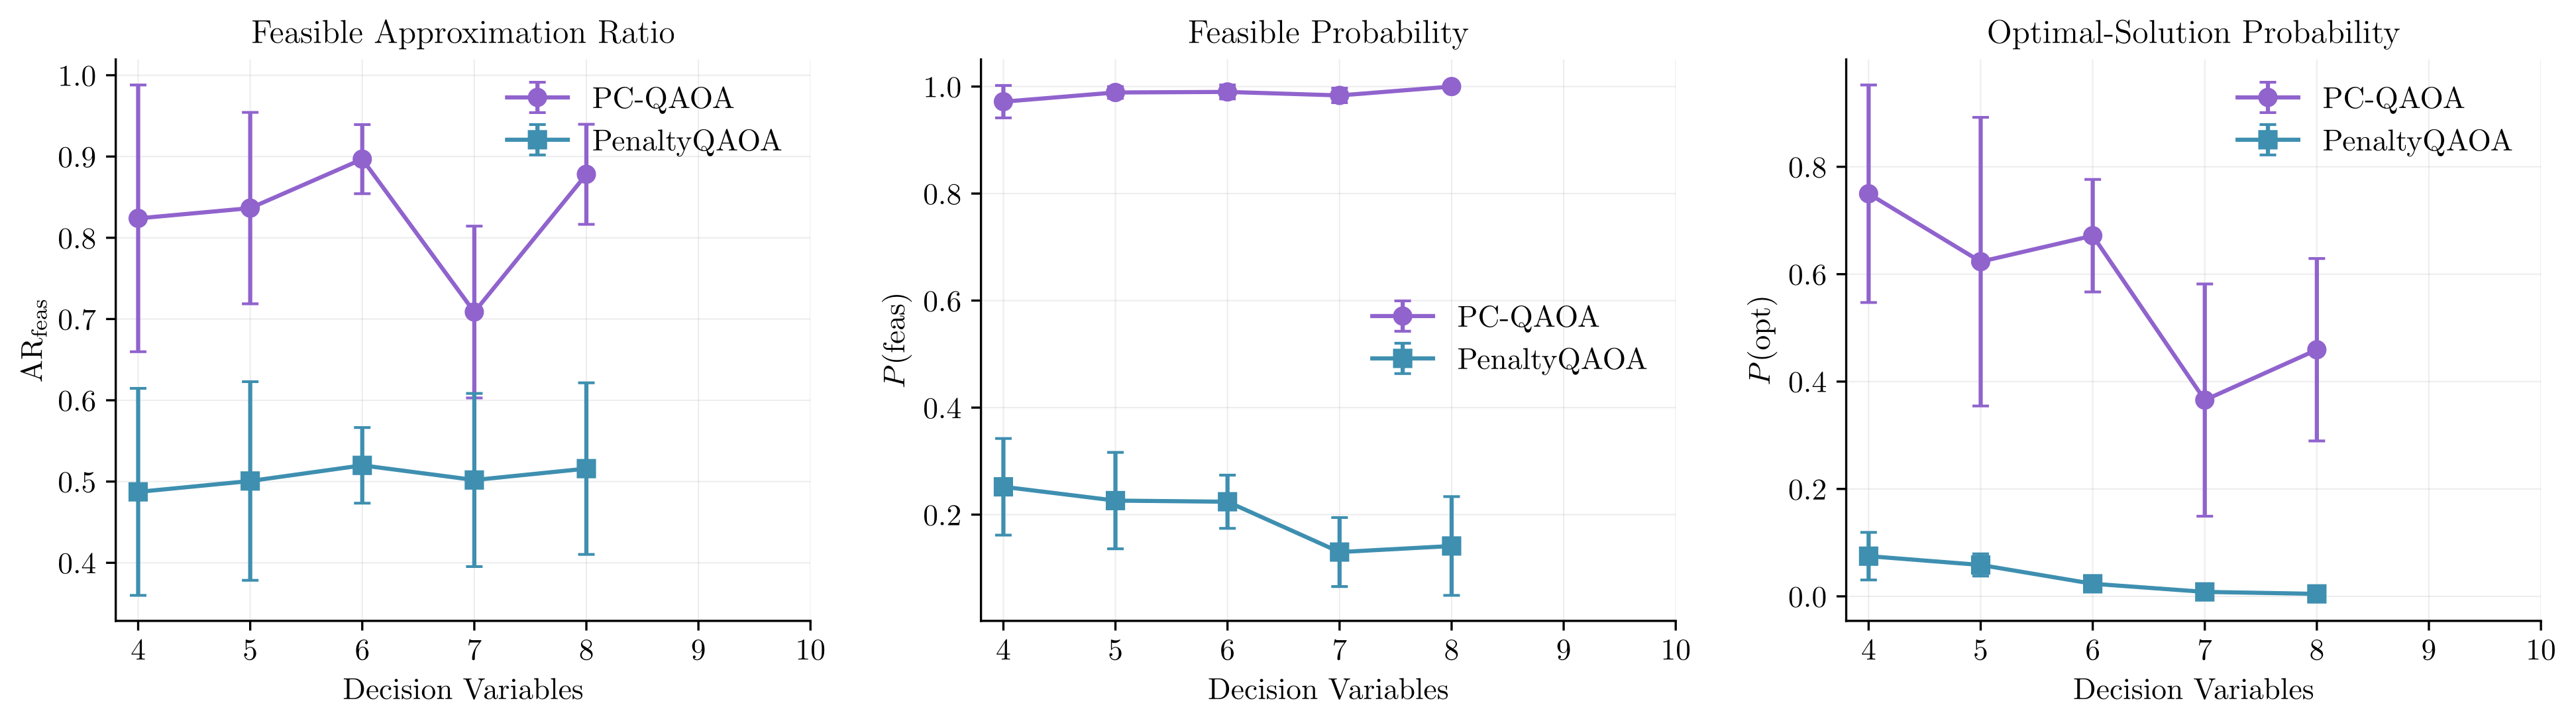

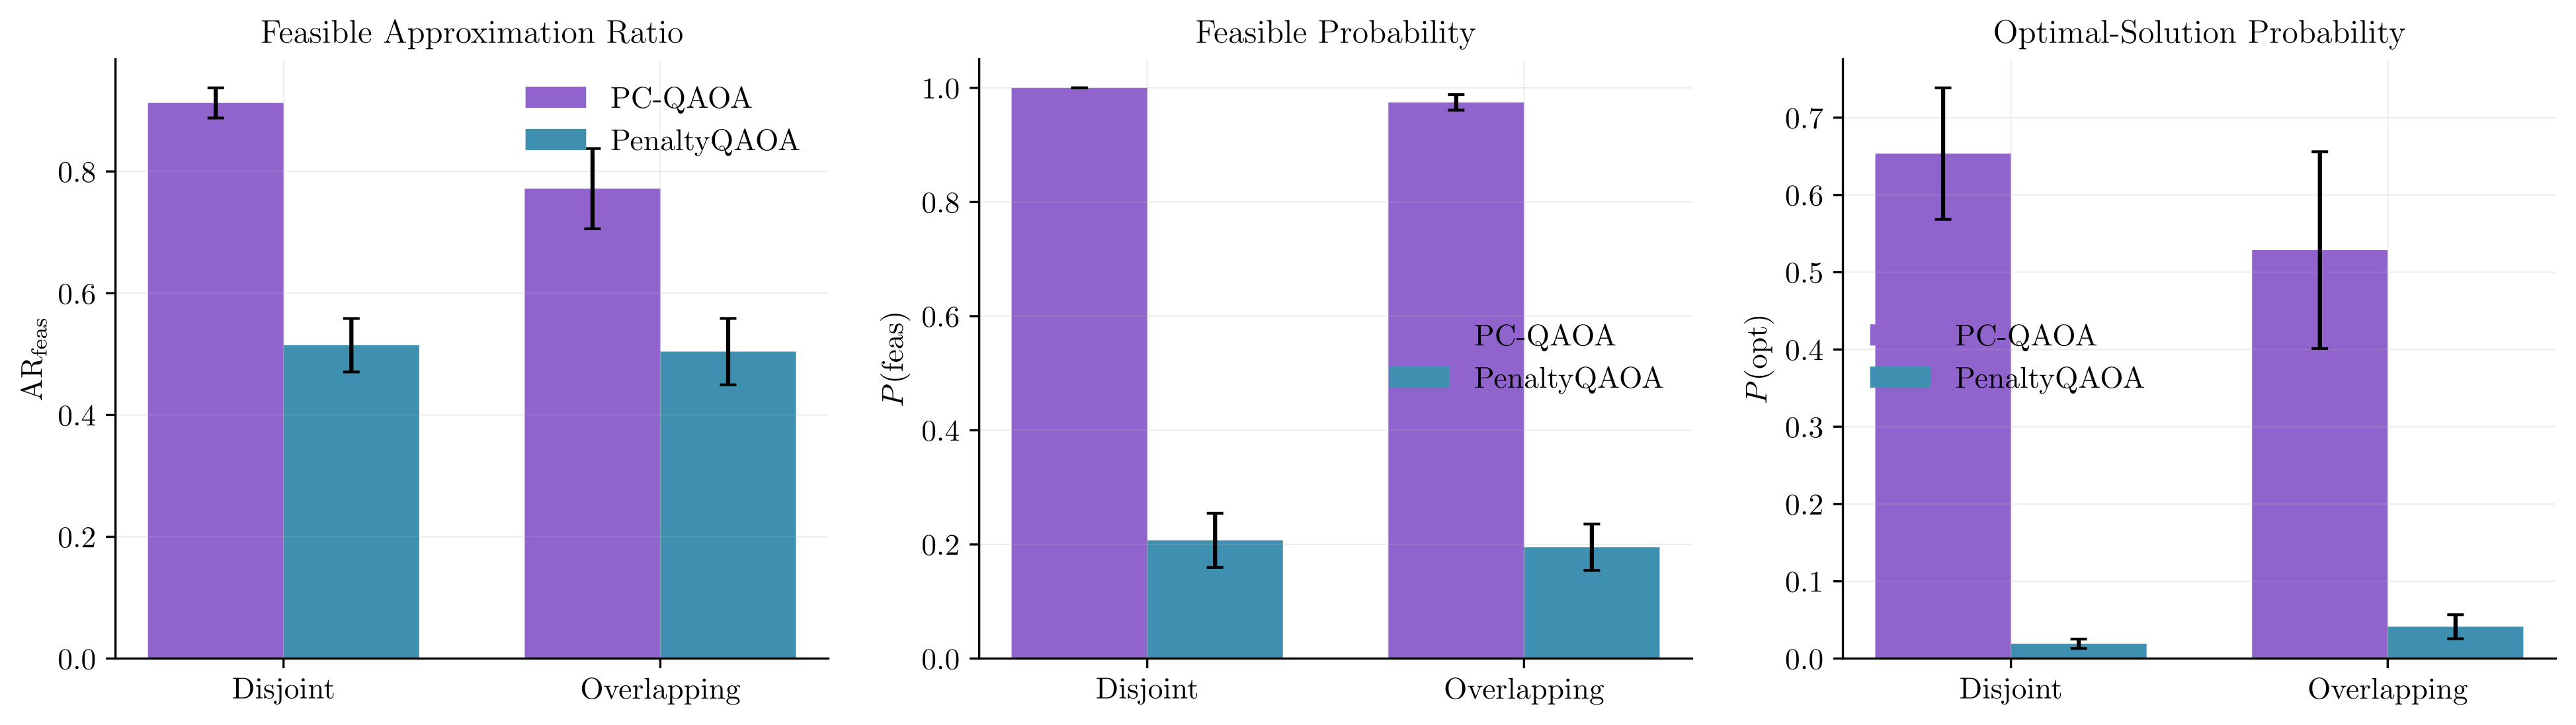

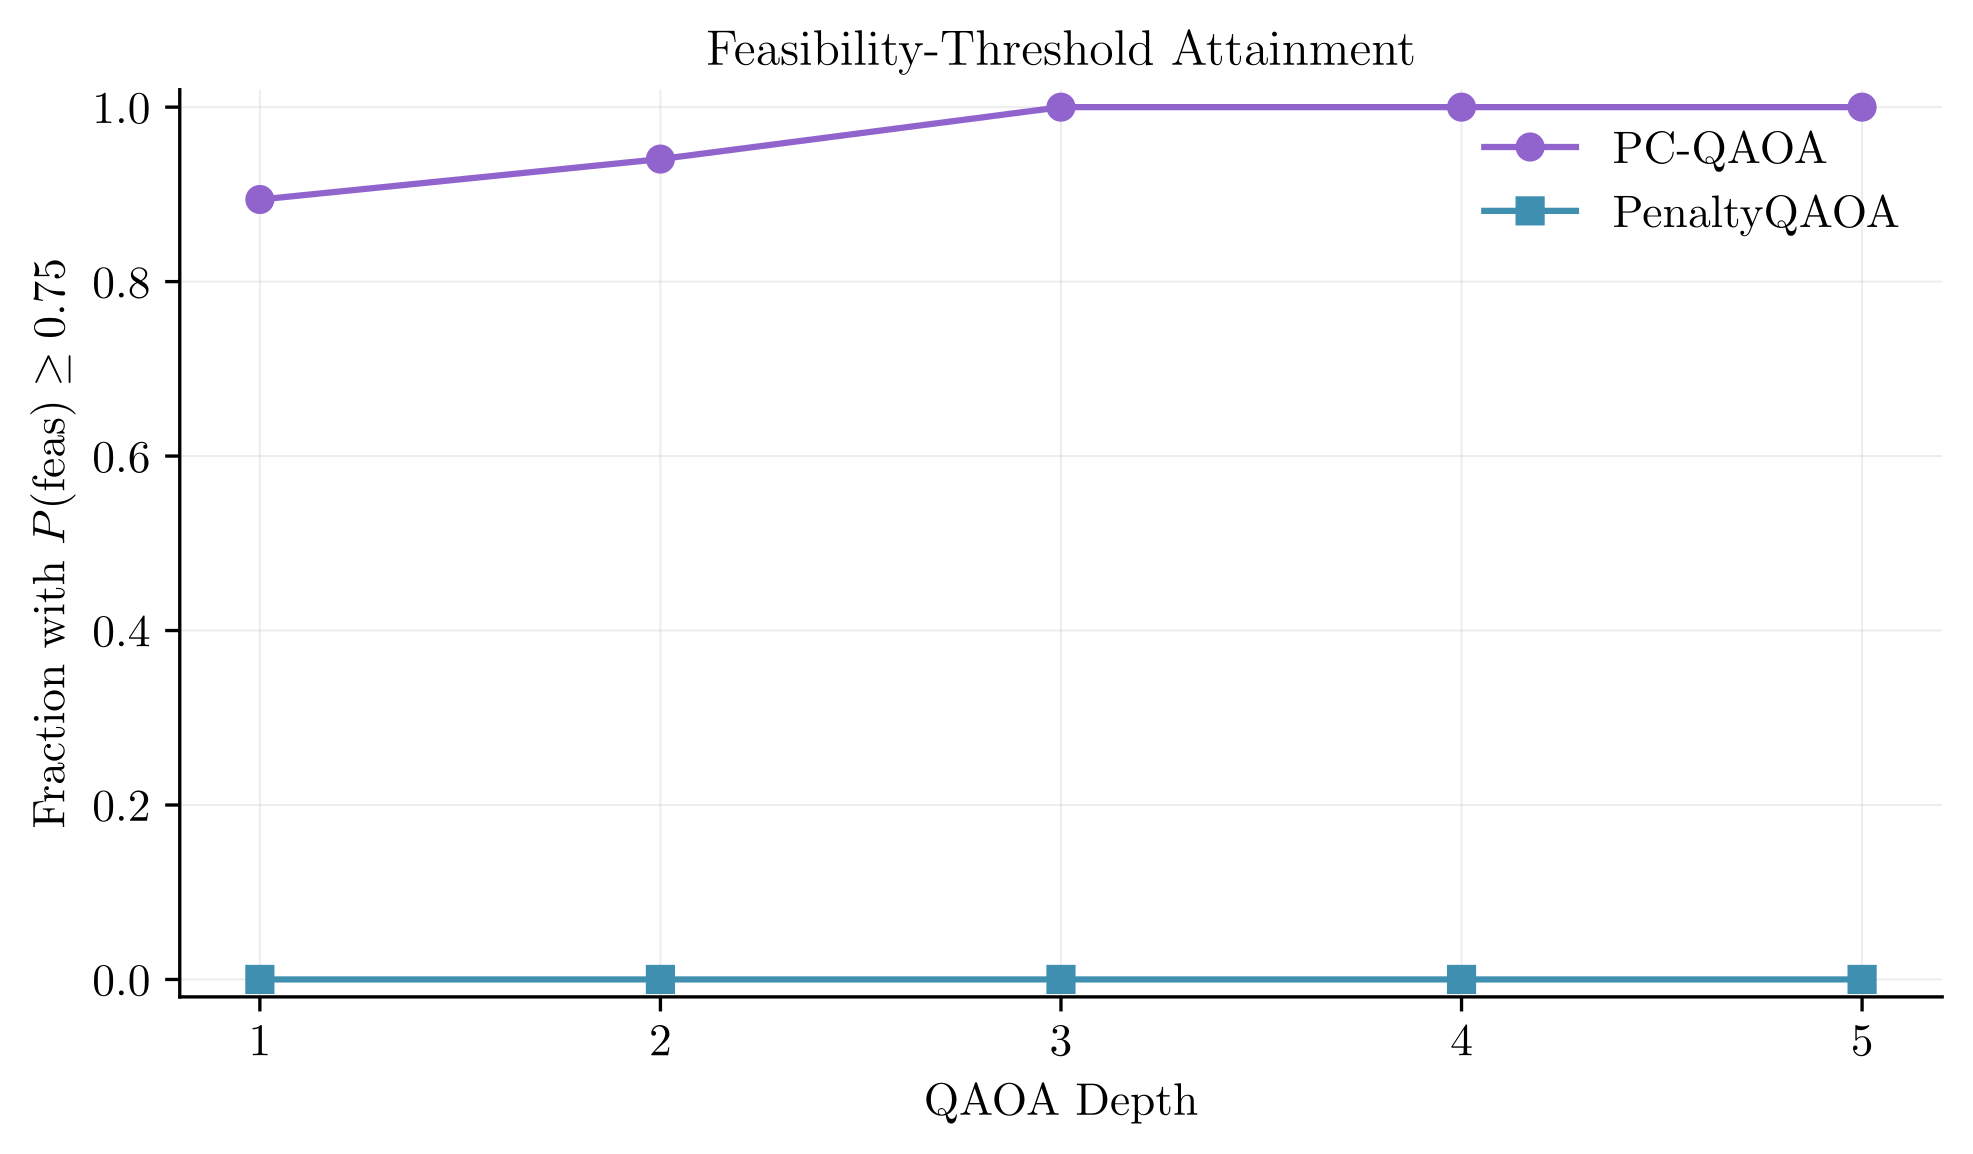

ar_feas                 p_feasible                  \
                              mean       std count       mean       std count   
method_label regime                                                             
PC-QAOA      disjoint     0.912539  0.080414    43   0.999977  0.000087    43   
             overlapping  0.771760  0.206005    40   0.974577  0.042513    40   
PenaltyQAOA  disjoint     0.514604  0.133605    38   0.207121  0.144573    38   
             overlapping  0.504111  0.158745    35   0.195086  0.118171    35   

                         p_optimal                  
                              mean       std count  
method_label regime                                 
PC-QAOA      disjoint     0.653456  0.276553    43  
             overlapping  0.528608  0.398235    40  
PenaltyQAOA  disjoint     0.019137  0.018504    38  
             overlapping  0.041183  0.045346    35

In [5]:
if depths.empty or not (depths["depth"] == 5).any():
    print("No depth-five results are available.")
else:
    final = depths[depths["depth"] == 5].copy()
    metrics = [
        ("ar_feas", r"$\mathrm{AR}_{\mathrm{feas}}$", "Feasible Approximation Ratio"),
        ("p_feasible", r"$P(\mathrm{feas})$", "Feasible Probability"),
        ("p_optimal", r"$P(\mathrm{opt})$", "Optimal-Solution Probability"),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.8))
    for ax, (metric, ylabel, title) in zip(axes, metrics):
        for method, subset in final.groupby("method_label", sort=False):
            stats = mean_ci(subset, "n_x", metric)
            ax.errorbar(stats["n_x"], stats["mean"], yerr=stats["ci95"].fillna(0),
                        color=COLORS[method], marker=MARKERS[method], linewidth=1.5,
                        capsize=3, label=method)
        ax.set(xlabel="Decision Variables", ylabel=ylabel, title=title)
        ax.set_xticks(sorted(instances["n_x"].unique()))
        ax.legend(frameon=False)
    writer.save(fig, "manuscript_metrics_by_size")

    fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.8))
    regimes = ["disjoint", "overlapping"]
    width = 0.36
    positions = np.arange(len(regimes))
    for ax, (metric, ylabel, title) in zip(axes, metrics):
        for offset, method in zip([-width / 2, width / 2], ["PC-QAOA", "PenaltyQAOA"]):
            subset = final[final["method_label"] == method]
            stats = mean_ci(subset, "regime", metric).set_index("regime").reindex(regimes)
            ax.bar(positions + offset, stats["mean"], width,
                   yerr=stats["ci95"].fillna(0), color=COLORS[method],
                   capsize=3, label=method)
        ax.set(xticks=positions, xticklabels=["Disjoint", "Overlapping"],
               ylabel=ylabel, title=title)
        ax.legend(frameon=False)
    writer.save(fig, "manuscript_metrics_by_regime")

    threshold = (depths.assign(reached=depths["p_feasible"] >= 0.75)
                 .groupby(["method_label", "depth"])["reached"]
                 .agg(["mean", "count"]).reset_index())
    fig, ax = plt.subplots(figsize=(6.8, 4.0))
    for method, subset in threshold.groupby("method_label", sort=False):
        ax.plot(subset["depth"], subset["mean"], color=COLORS[method],
                marker=MARKERS[method], linewidth=1.5, label=method)
    ax.set(xlabel="QAOA Depth", ylabel=r"Fraction with $P(\mathrm{feas})\geq 0.75$",
           title="Feasibility-Threshold Attainment", ylim=(-0.02, 1.02))
    ax.set_xticks(sorted(depths["depth"].unique()))
    ax.legend(frameon=False)
    writer.save(fig, "feasibility_threshold_by_depth")

    display(final.groupby(["method_label", "regime"])
            [["ar_feas", "p_feasible", "p_optimal"]].agg(["mean", "std", "count"]))

## Paired Final-Depth Comparison

The table and difference plot compare the two methods on the same COPs. A positive difference means PC-QAOA has higher sampled $P(\mathrm{opt})$. Results are separated by decision size and by disjoint or overlapping constraint supports.

,PC-QAOA,PenaltyQAOA,n_x,support,m,o,Difference
count,73.000000,73.000000,73.000000,73.0,73.000000,73.000000,73.000000
mean,0.614334,0.029707,6.041096,4.0,2.356164,0.671233,0.584627
std,0.340822,0.035637,1.183666,0.0,0.482179,0.782709,0.331536
min,0.017300,0.000300,4.000000,4.0,2.000000,0.000000,-0.003000
25%,0.241300,0.007600,5.000000,4.0,2.000000,0.000000,0.235200
50%,0.682000,0.016600,6.000000,4.0,2.000000,0.000000,0.646500
75%,0.951400,0.040100,7.000000,4.0,3.000000,1.000000,0.890700
max,1.000000,0.248600,8.000000,4.0,3.000000,2.000000,0.994500


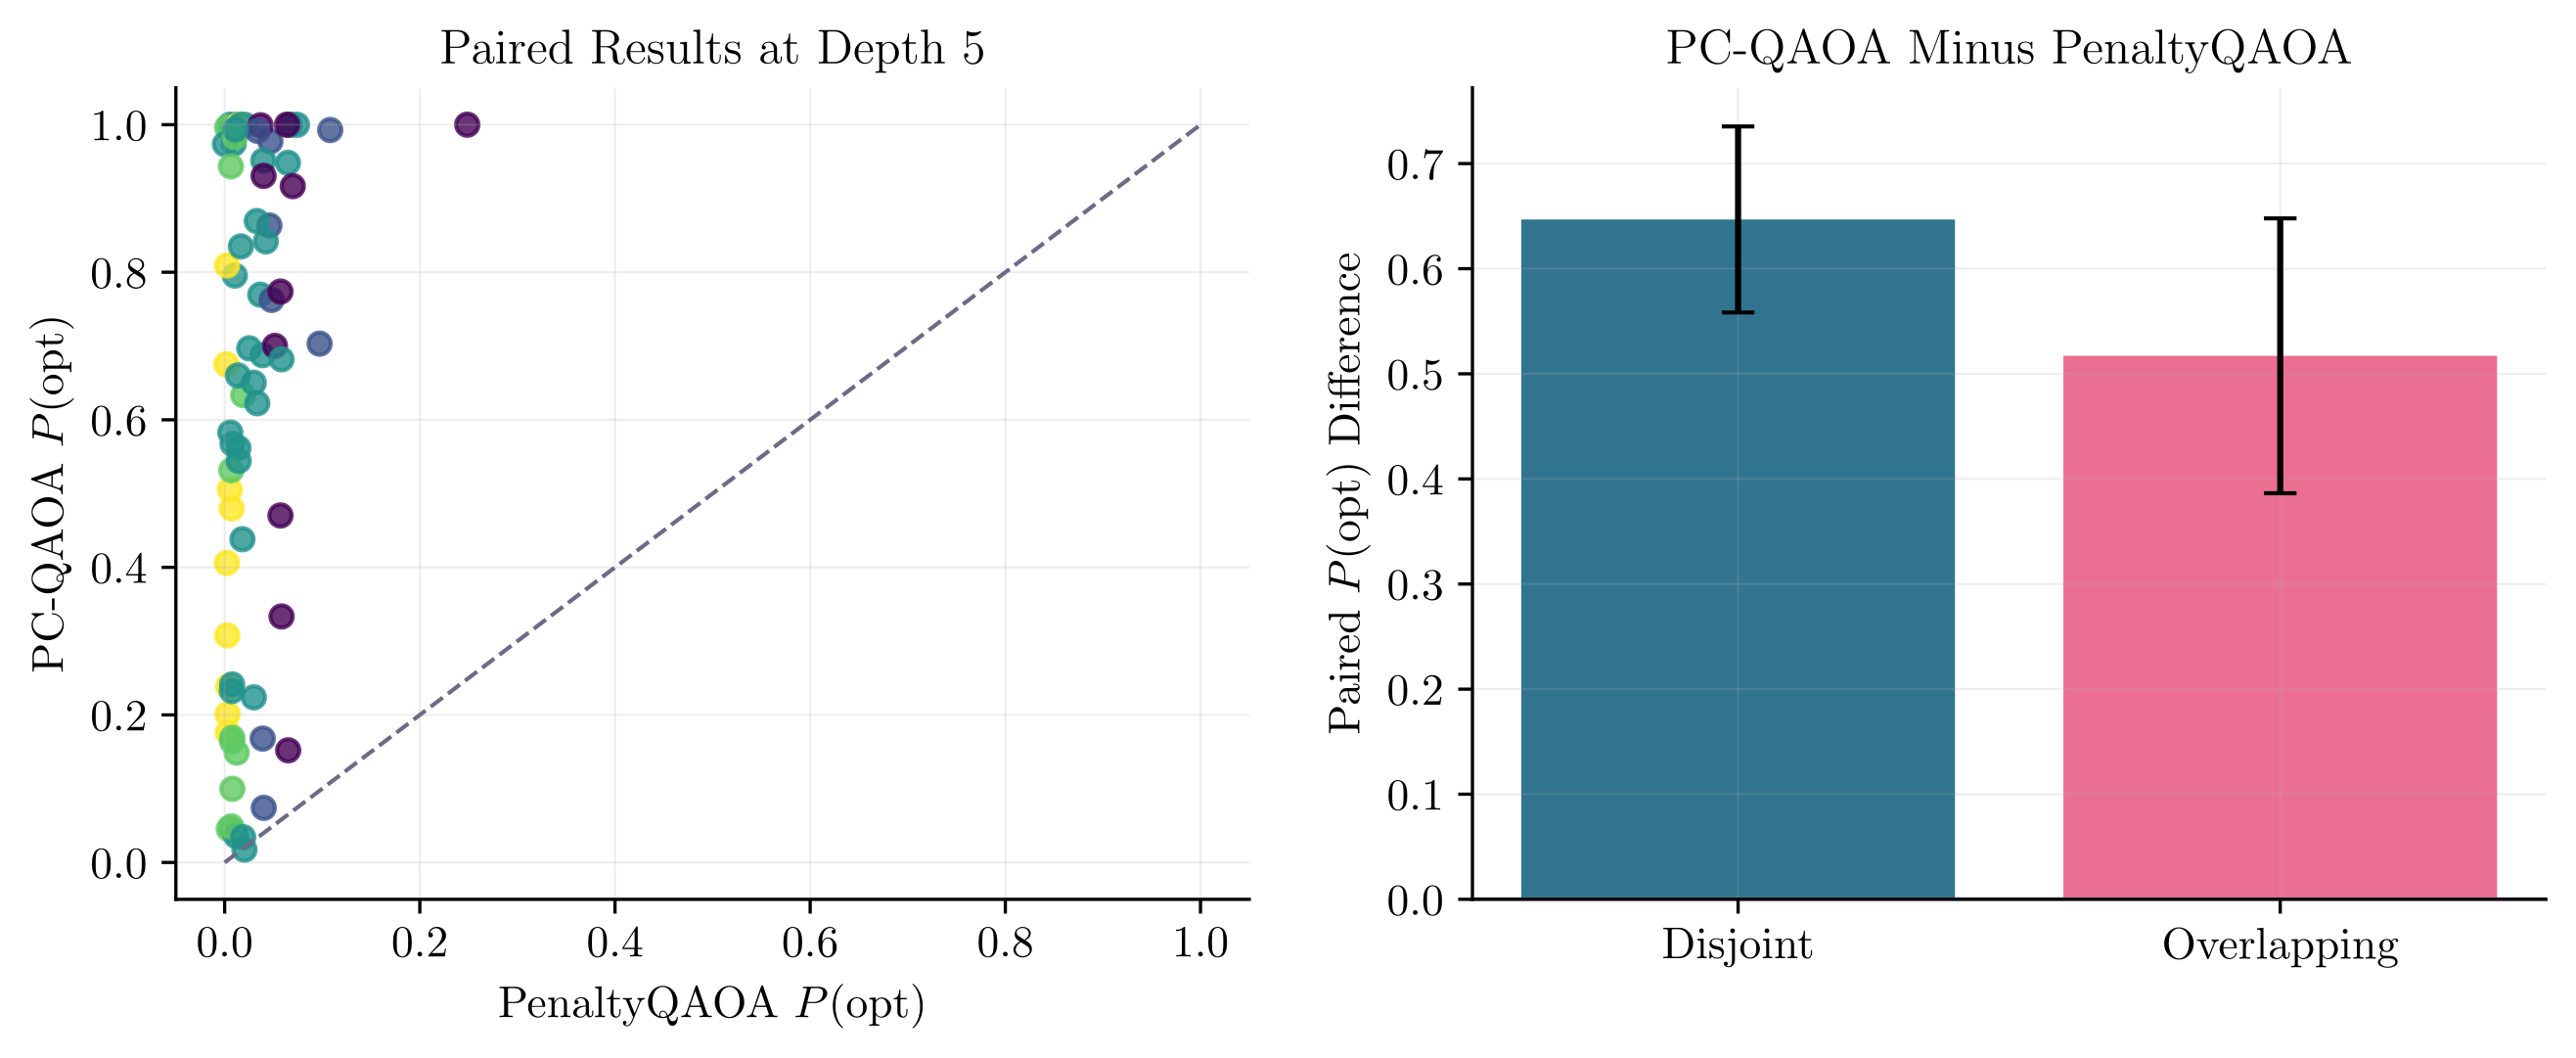

PC-QAOA       PenaltyQAOA      
         mean count        mean count
n_x                                  
4    0.727620    10    0.074830    10
5    0.725867     9    0.058456     9
6    0.669691    32    0.023406    32
7    0.400708    12    0.008283    12
8    0.479880    10    0.004580    10

In [6]:
if depths.empty:
    print("No paired depth results are available.")
else:
    final_depth = int(depths["depth"].max())
    final = depths[depths["depth"] == final_depth]
    paired = final.pivot(index="instance_id", columns="method_label", values="p_optimal")
    required = {"PC-QAOA", "PenaltyQAOA"}
    if not required.issubset(paired.columns):
        paired = pd.DataFrame()
    else:
        paired = paired[["PC-QAOA", "PenaltyQAOA"]].dropna()
        paired = paired.join(instances.set_index("id")[["n_x", "regime", "support", "m", "o"]])
    if paired.empty:
        print("No COP has results from both methods at the final available depth.")
    else:
        paired["Difference"] = paired["PC-QAOA"] - paired["PenaltyQAOA"]
        display(paired.describe())
        fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
        axes[0].scatter(paired["PenaltyQAOA"], paired["PC-QAOA"],
                        c=paired["n_x"], cmap="viridis", s=30, alpha=0.8)
        bound = max(paired[["PC-QAOA", "PenaltyQAOA"]].to_numpy().max(), 1e-3)
        axes[0].plot([0, bound], [0, bound], "--", color=COLORS["Gray"], linewidth=1)
        axes[0].set(xlabel=r"PenaltyQAOA $P(\mathrm{opt})$",
                    ylabel=r"PC-QAOA $P(\mathrm{opt})$",
                    title=f"Paired Results at Depth {final_depth}")
        groups = [paired.loc[paired.regime == name, "Difference"]
                  for name in ["disjoint", "overlapping"]]
        means = [group.mean() for group in groups]
        errors = [t.ppf(0.975, len(group)-1) * group.std(ddof=1) / np.sqrt(len(group))
                  if len(group) > 1 else np.nan for group in groups]
        axes[1].bar(["Disjoint", "Overlapping"], means, yerr=np.nan_to_num(errors),
                    color=[COLORS["Disjoint"], COLORS["Overlapping"]], capsize=4)
        axes[1].axhline(0, color=COLORS["Gray"], linewidth=1)
        axes[1].set(ylabel=r"Paired $P(\mathrm{opt})$ Difference",
                    title="PC-QAOA Minus PenaltyQAOA")
        writer.save(fig, "paired_final_depth")

        by_size = paired.groupby("n_x")[["PC-QAOA", "PenaltyQAOA"]].agg(["mean", "count"])
        display(by_size)

## Sampled and Exact Probabilities

Points on the diagonal have equal sampled and exact probabilities. Differences arise from finite measurement shots.

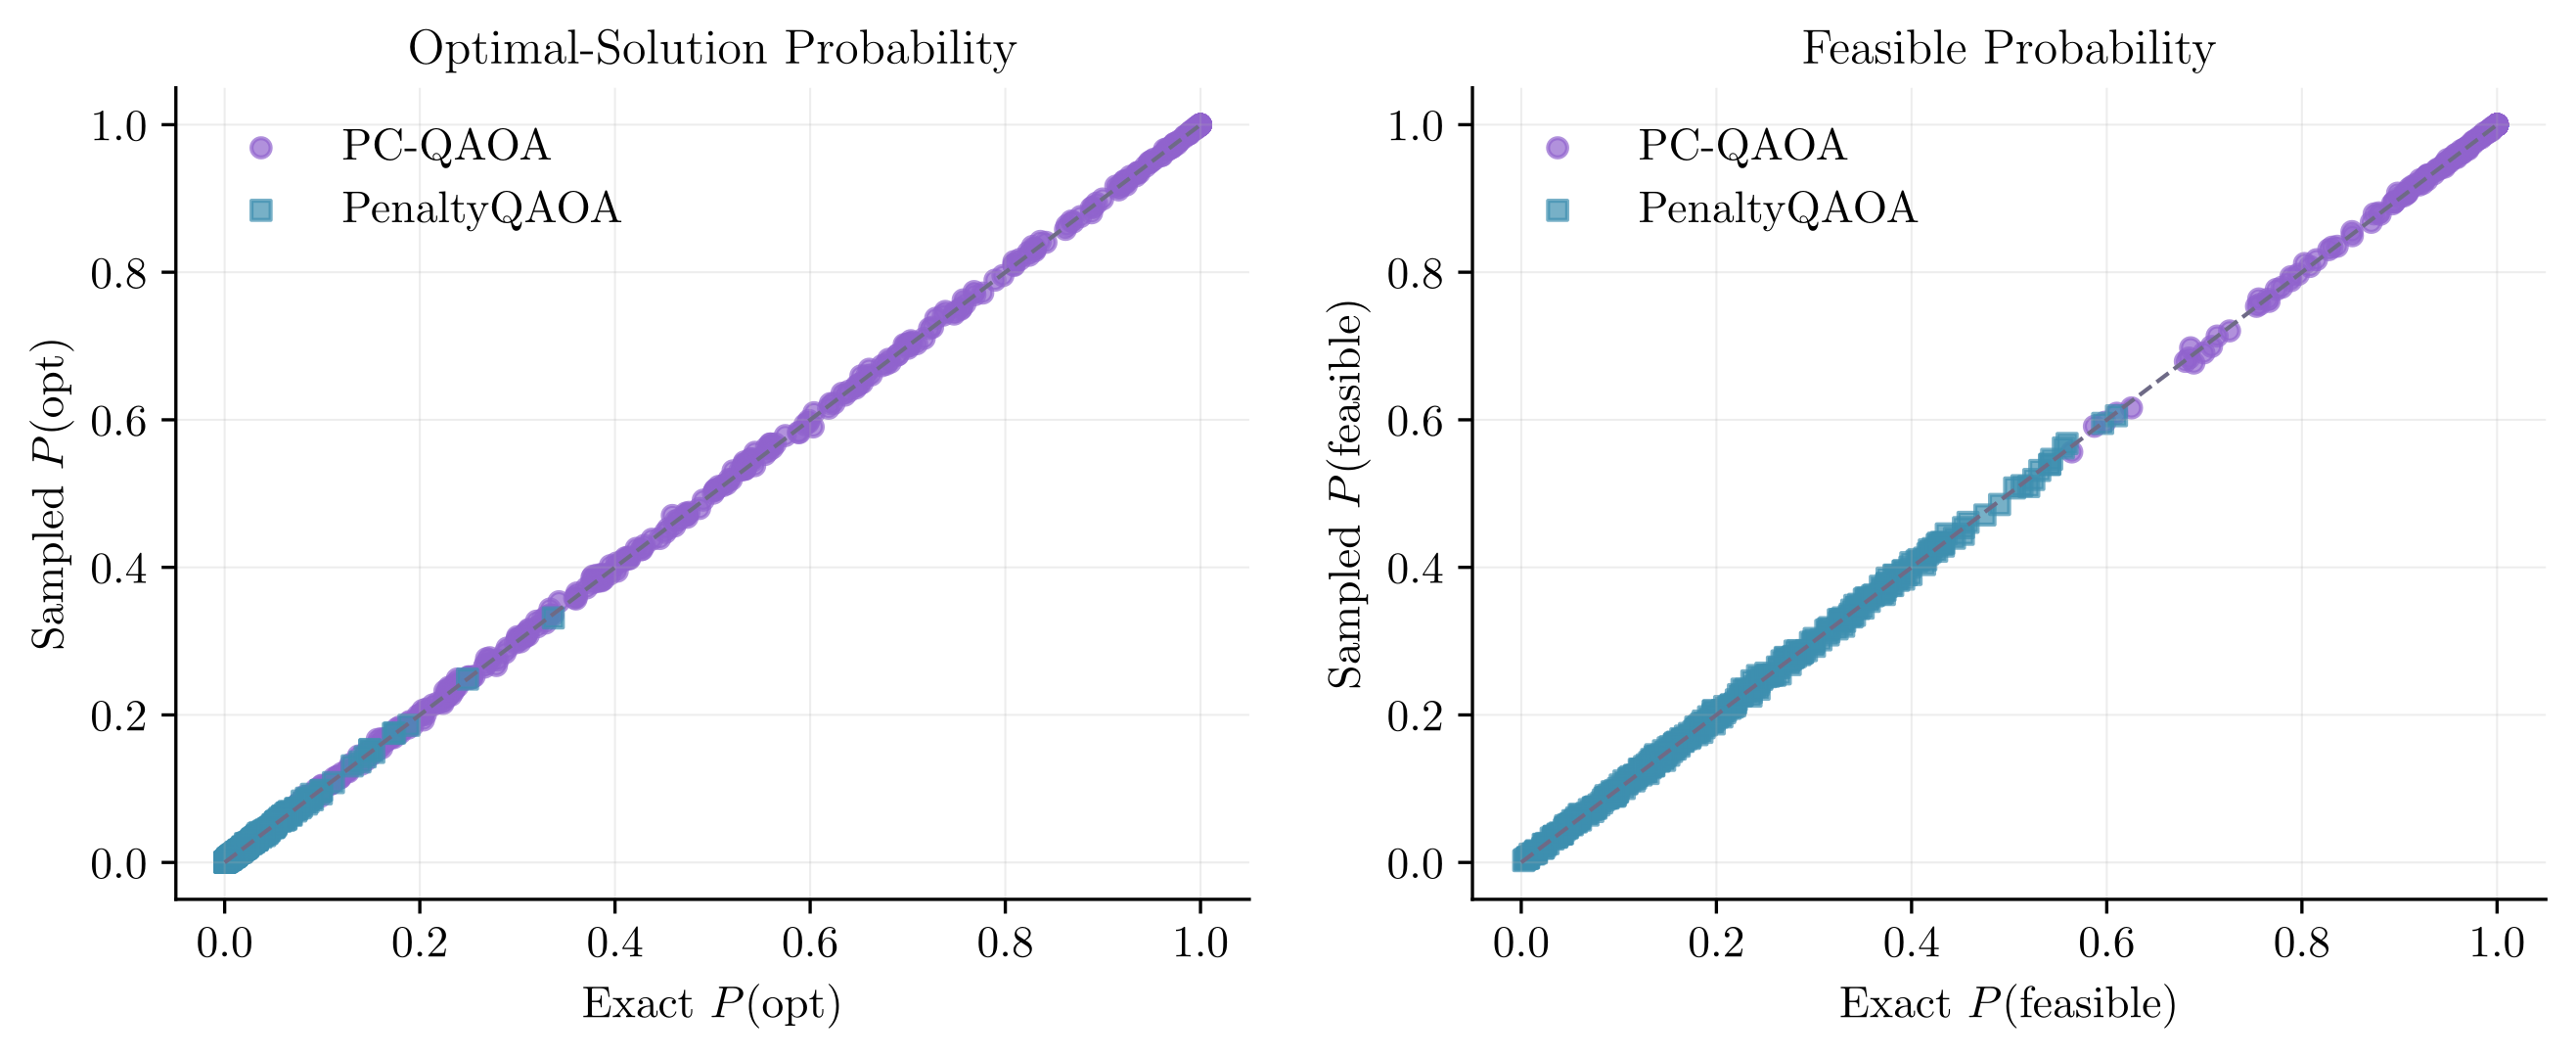

In [7]:
if depths.empty:
    print("No probability results are available.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
    for method, subset in depths.groupby("method_label", sort=False):
        axes[0].scatter(subset["exact_p_optimal"], subset["p_optimal"],
                        color=COLORS[method], marker=MARKERS[method],
                        s=22, alpha=0.7, label=method)
        axes[1].scatter(subset["exact_p_feasible"], subset["p_feasible"],
                        color=COLORS[method], marker=MARKERS[method],
                        s=22, alpha=0.7, label=method)
    for ax, label in zip(axes, [r"$P(\mathrm{opt})$", r"$P(\mathrm{feasible})$"]):
        ax.plot([0, 1], [0, 1], "--", color=COLORS["Gray"], linewidth=1)
        ax.set(xlabel=f"Exact {label}", ylabel=f"Sampled {label}")
        ax.legend(frameon=False)
    axes[0].set_title("Optimal-Solution Probability")
    axes[1].set_title("Feasible Probability")
    writer.save(fig, "sampled_exact_probabilities")

## PenaltyQAOA Diagnostics

The first panel compares the selected coefficient-range penalty

$$
\delta_{\mathrm{range}}=U_Q-L_Q+1
$$

with the manuscript rule $\delta_{\mathrm{manuscript}}=5+2|f_{\min}|$. The second panel compares the depth-five feasible probability with the fraction of feasible decision strings. These plots describe the current instances. They do not isolate the effects of the penalty rule, angle parameterization, and dataset.

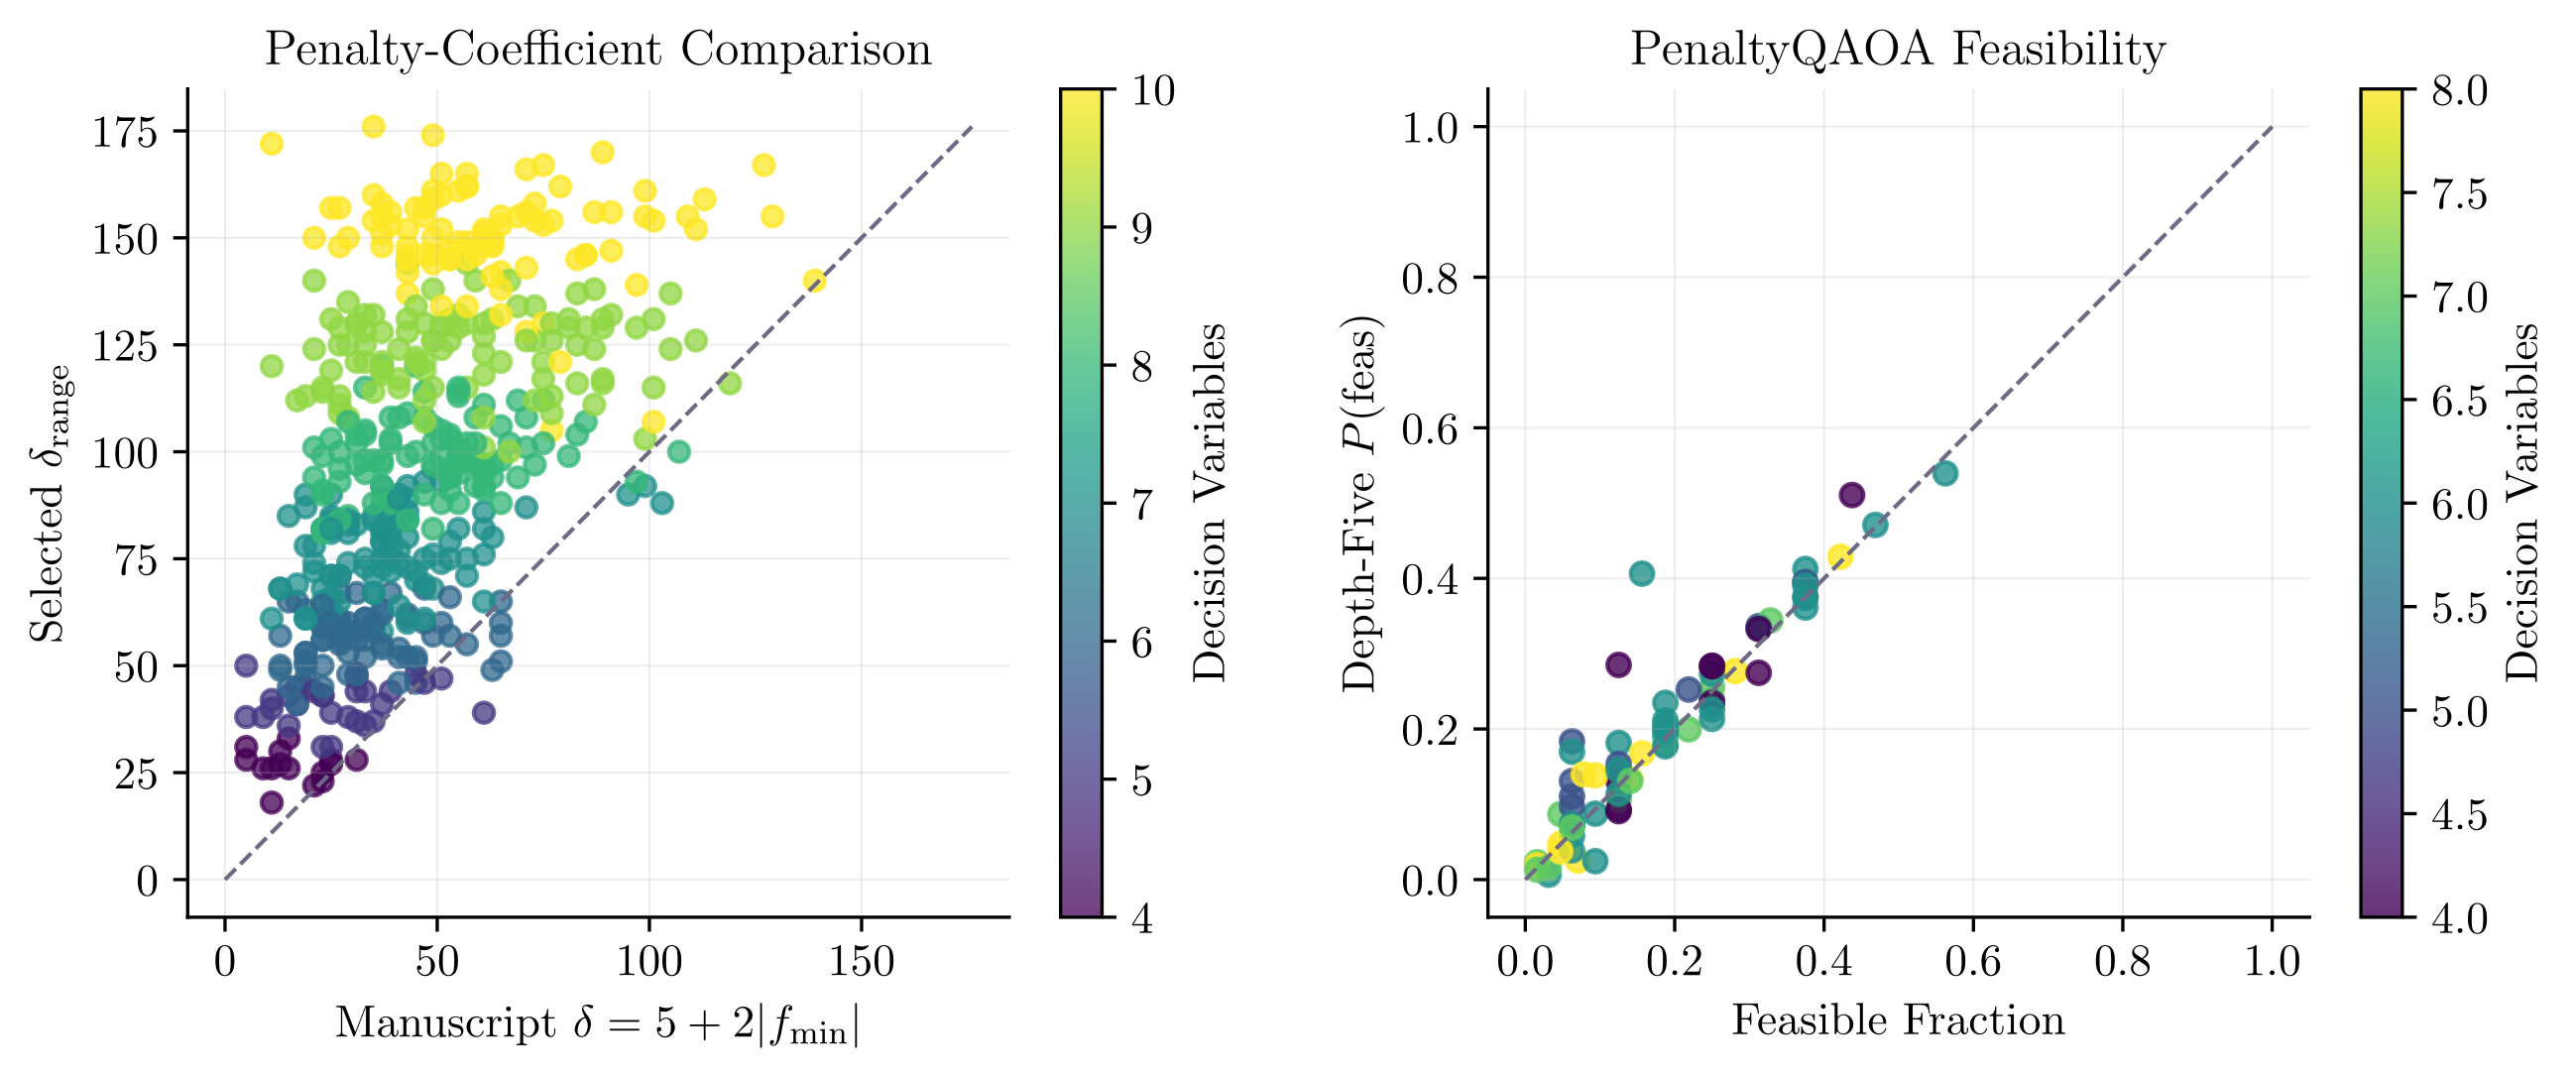

,count,mean,std,min,25%,50%,75%,max
n_x,73.0,6.041096,1.183666,4.000000,5.000000,6.000000,7.000000,8.000000
n_total,73.0,8.561644,1.957793,4.000000,7.000000,9.000000,10.000000,13.000000
delta,73.0,60.739726,23.874107,18.000000,47.000000,58.000000,72.000000,120.000000
manuscript_delta,73.0,33.575342,16.981949,5.000000,21.000000,31.000000,43.000000,81.000000
feasible_fraction,73.0,0.186109,0.127027,0.015625,0.070312,0.156250,0.250000,0.562500
p_feasible,73.0,0.201351,0.131802,0.006500,0.097300,0.181500,0.283200,0.539500
p_optimal,73.0,0.029707,0.035637,0.000300,0.007600,0.016600,0.040100,0.248600
ar_feas,73.0,0.509573,0.145261,0.108696,0.410714,0.493603,0.587992,0.871975


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
delta_points = axes[0].scatter(
    instances["manuscript_delta"], instances["delta"],
    c=instances["n_x"], cmap="viridis", s=24, alpha=0.75)
fig.colorbar(delta_points, ax=axes[0], label="Decision Variables")
bound = float(max(instances["manuscript_delta"].max(), instances["delta"].max()))
axes[0].plot([0, bound], [0, bound], "--", color=COLORS["Gray"], linewidth=1)
axes[0].set(xlabel=r"Manuscript $\delta=5+2|f_{\min}|$",
            ylabel=r"Selected $\delta_{\mathrm{range}}$",
            title="Penalty-Coefficient Comparison")

penalty_final = (depths[(depths["method_label"] == "PenaltyQAOA") &
                        (depths["depth"] == 5)].copy()
                 if not depths.empty else pd.DataFrame())
if penalty_final.empty:
    axes[1].text(0.5, 0.5, "No Completed Depth-Five Results",
                 ha="center", va="center", transform=axes[1].transAxes)
else:
    feasibility_points = axes[1].scatter(
        penalty_final["feasible_fraction"], penalty_final["p_feasible"],
        c=penalty_final["n_x"], cmap="viridis", s=30, alpha=0.8)
    fig.colorbar(feasibility_points, ax=axes[1], label="Decision Variables")
    axes[1].plot([0, 1], [0, 1], "--", color=COLORS["Gray"], linewidth=1)
axes[1].set(xlabel="Feasible Fraction", ylabel=r"Depth-Five $P(\mathrm{feas})$",
            title="PenaltyQAOA Feasibility")
writer.save(fig, "penaltyqaoa_diagnostics")

if not penalty_final.empty:
    display(penalty_final[["instance_id", "n_x", "n_total", "delta", "manuscript_delta",
                           "feasible_fraction", "p_feasible", "p_optimal",
                           "ar_feas"]].describe().T)

## Qubits and Runtime

PC-QAOA uses slack qubits only for constraints assigned to its penalty Hamiltonian. PenaltyQAOA encodes every constraint in its penalty Hamiltonian. Runtime plots report recorded optimizer time and the peak resident memory of each worker process.

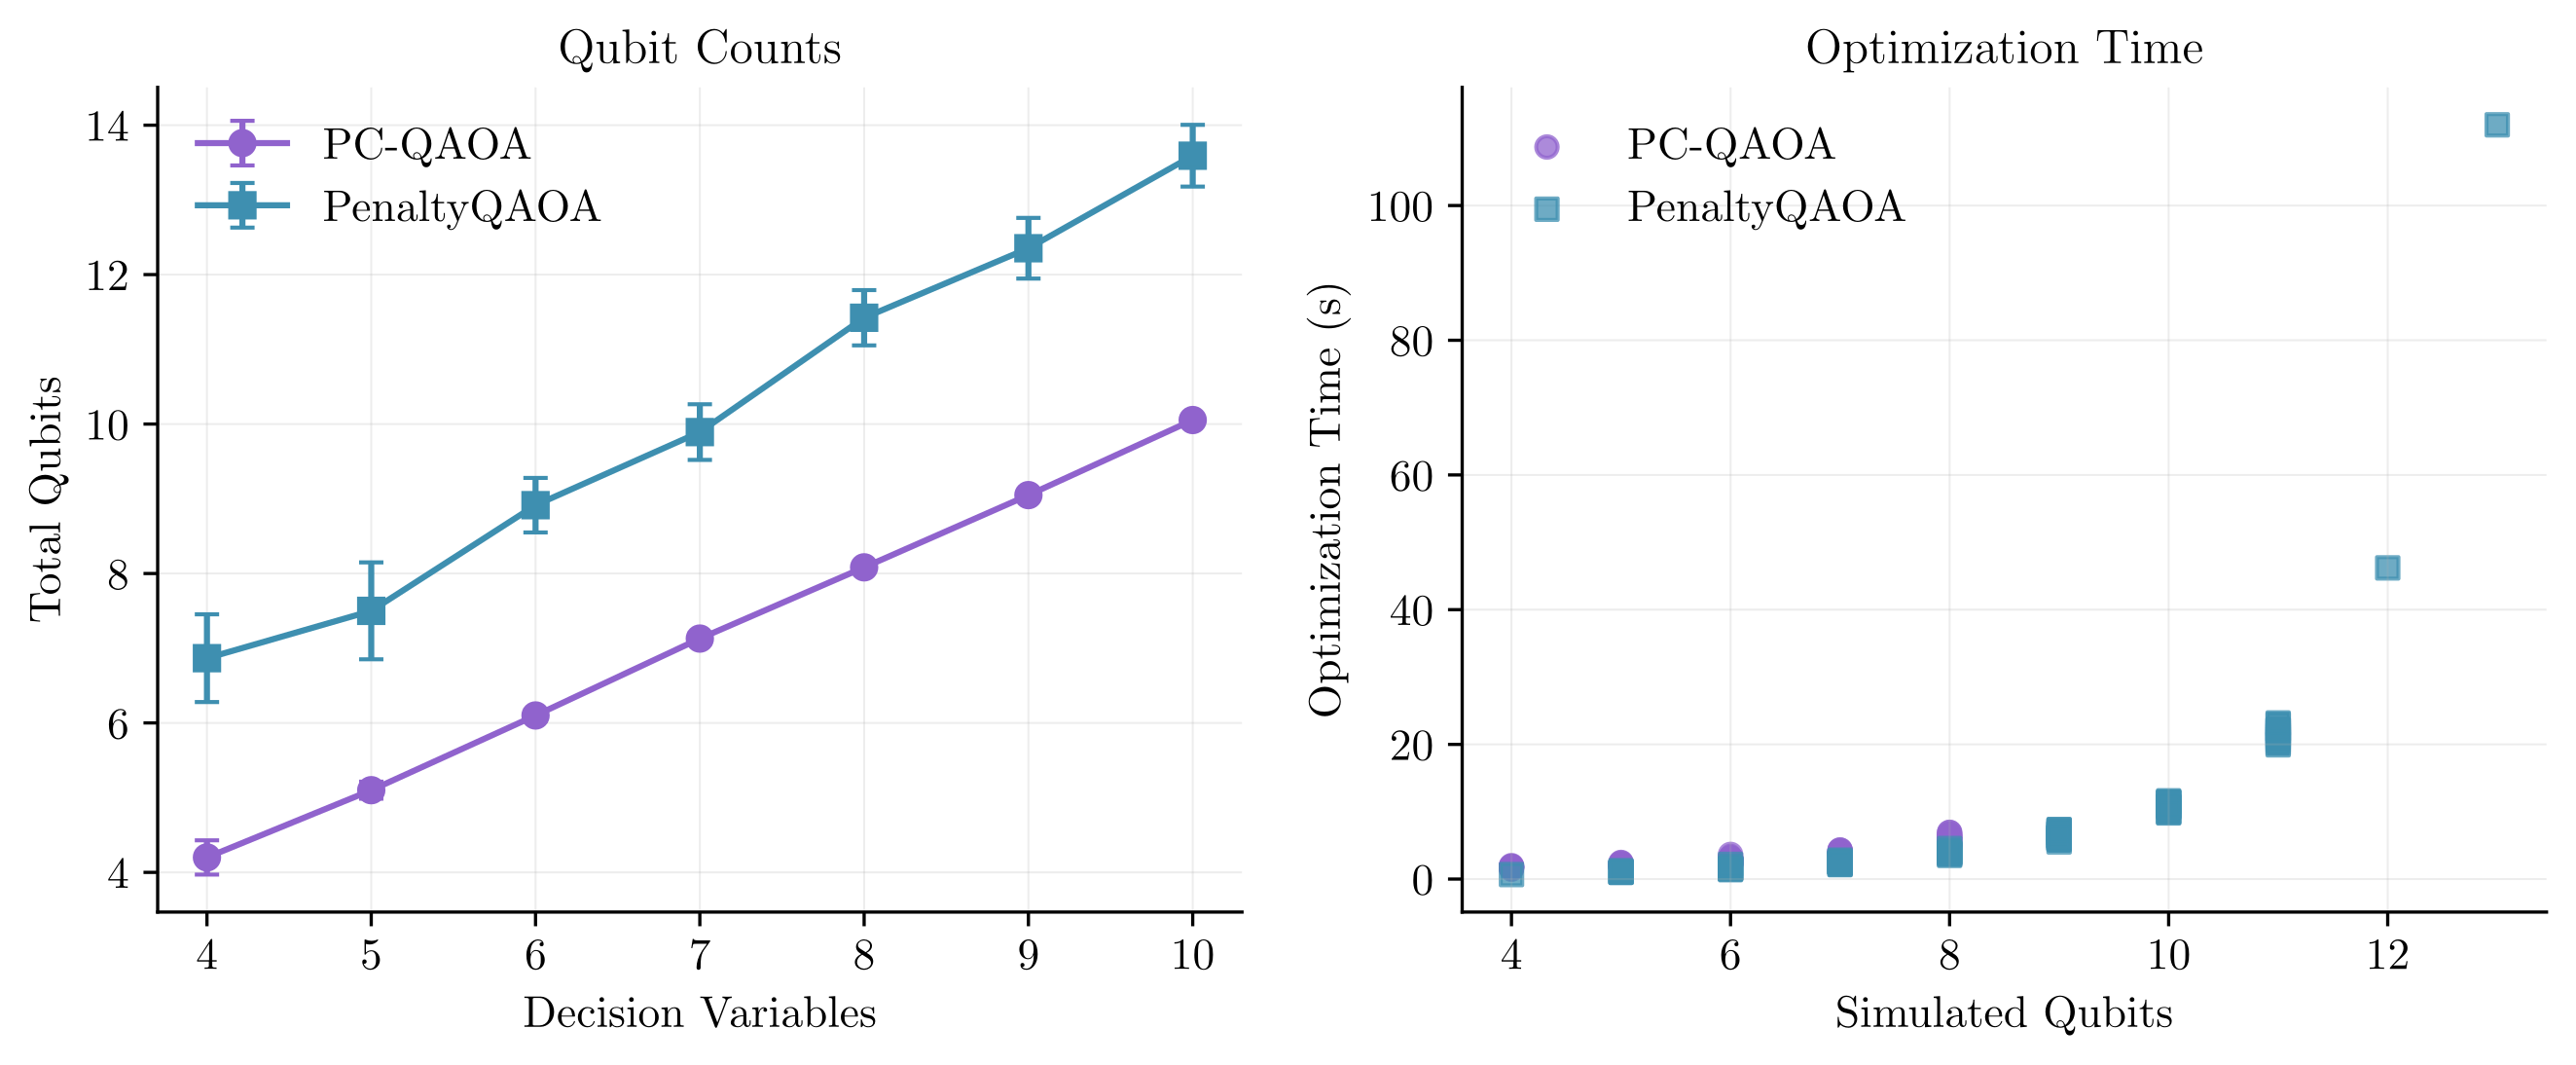

compile_seconds                  optimize_seconds             \
                        mean        std count             mean        std   
method_label                                                                
PC-QAOA            24.490585   6.667600    83         3.269498   1.489888   
PenaltyQAOA        34.763342  13.173659    73         9.672244  14.543888   

                   process_peak_rss_mb                    
             count                mean         std count  
method_label                                              
PC-QAOA         83          673.085938   60.327442    83  
PenaltyQAOA     73          777.967894  136.163826    73

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
qubits = instances[["n_x", "n_total_pcqaoa", "n_total_penaltyqaoa"]].melt(
    id_vars="n_x", var_name="Method", value_name="Total Qubits")
qubits["Method"] = qubits["Method"].map({"n_total_pcqaoa": "PC-QAOA",
                                           "n_total_penaltyqaoa": "PenaltyQAOA"})
for method, subset in qubits.groupby("Method", sort=False):
    stats = mean_ci(subset, "n_x", "Total Qubits")
    axes[0].errorbar(stats["n_x"], stats["mean"], yerr=stats["ci95"].fillna(0),
                     color=COLORS[method], marker=MARKERS[method], capsize=3,
                     linewidth=1.5, label=method)
axes[0].set(xlabel="Decision Variables", ylabel="Total Qubits",
            title="Qubit Counts")
axes[0].set_xticks(sorted(instances["n_x"].unique()))
axes[0].legend(frameon=False)

if results.empty:
    axes[1].text(0.5, 0.5, "No Completed Results", ha="center", va="center",
                 transform=axes[1].transAxes)
else:
    for method, subset in results.groupby("method_label", sort=False):
        axes[1].scatter(subset["n_total"], subset["optimize_seconds"],
                        color=COLORS[method], marker=MARKERS[method], s=28,
                        alpha=0.75, label=method)
    axes[1].legend(frameon=False)
axes[1].set(xlabel="Simulated Qubits", ylabel="Optimization Time (s)",
            title="Optimization Time")
writer.save(fig, "qubits_runtime")

if not results.empty:
    display(results.groupby("method_label")[["compile_seconds", "optimize_seconds",
                                             "process_peak_rss_mb"]].agg(["mean", "std", "count"]))

## Example Optimization History

Each curve is one optimizer restart for one COP, method, and depth. The retained restart has the lowest final penalized expectation at that depth. The vertical axis is the training objective.

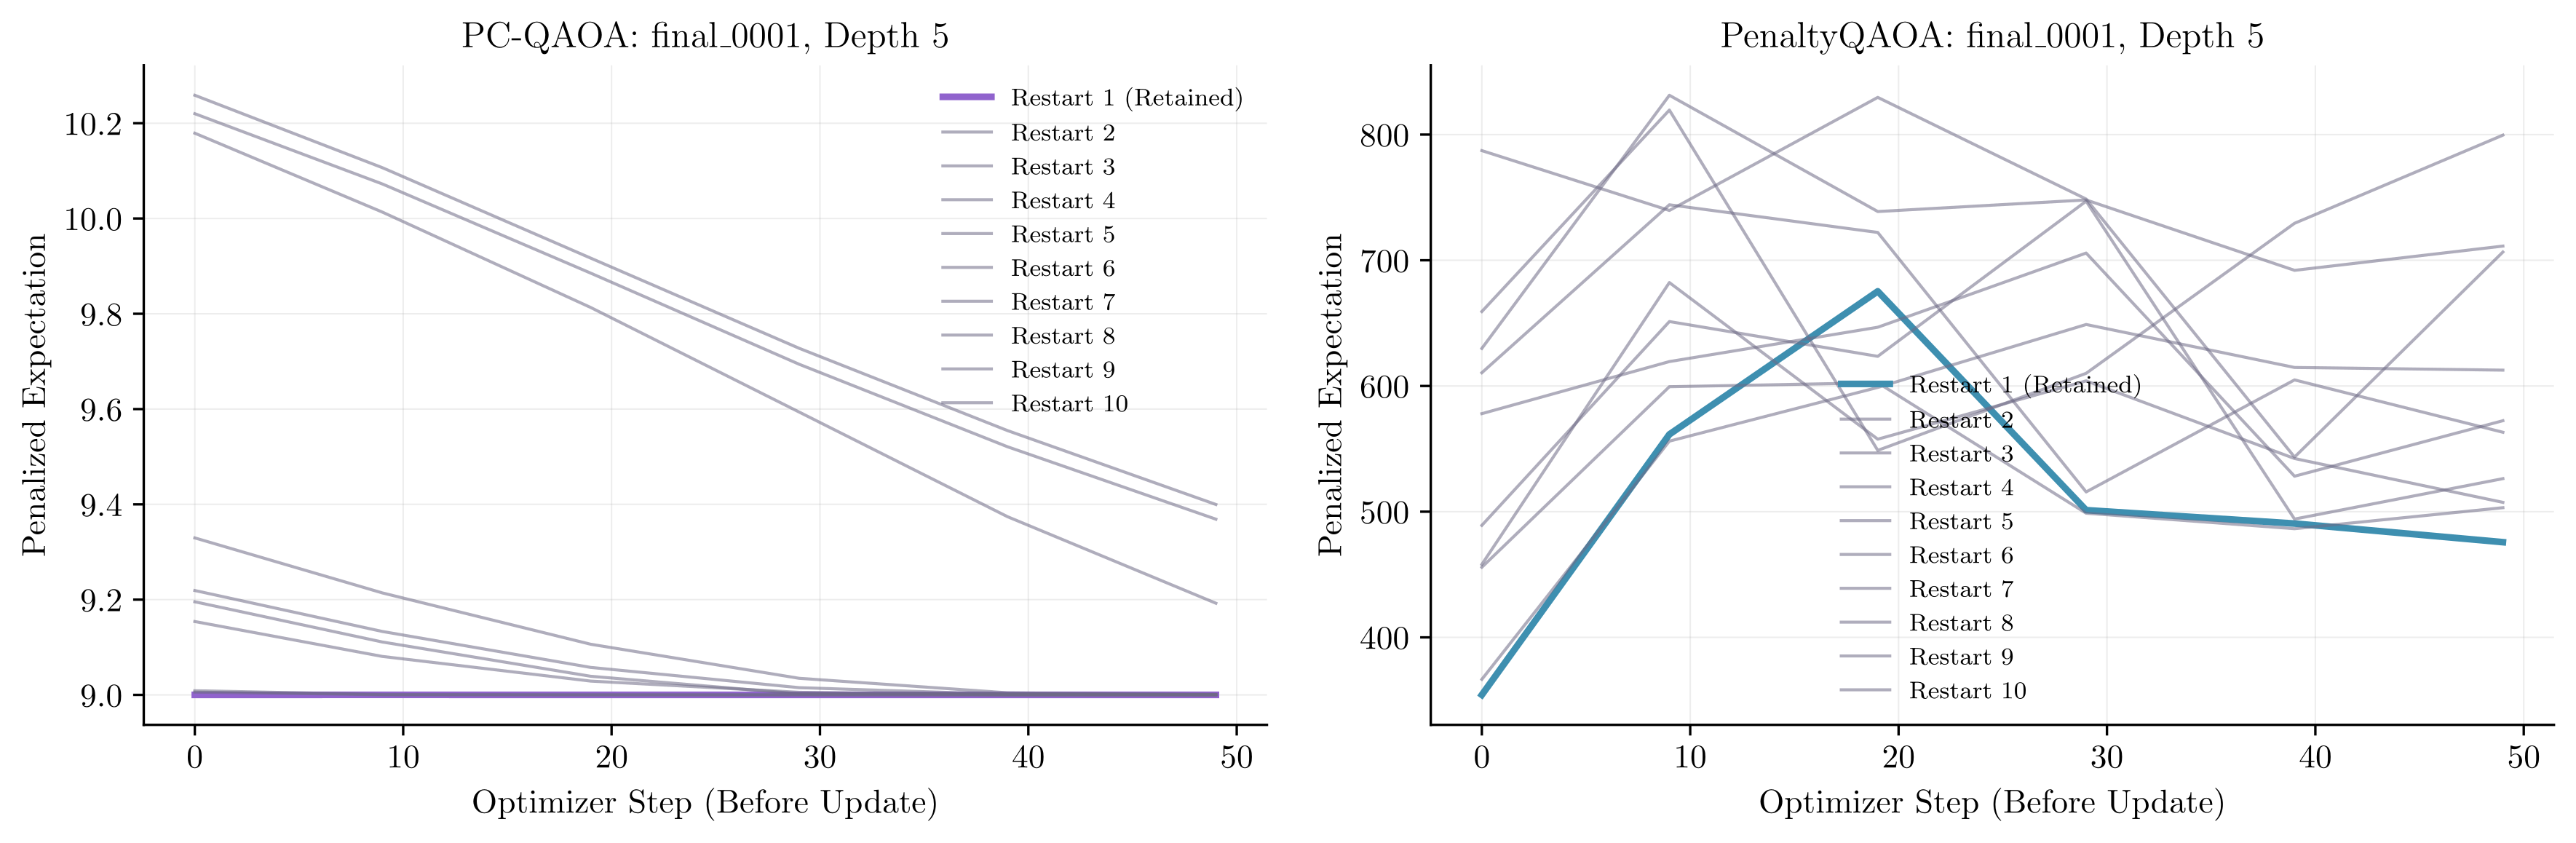

In [10]:
def history_path(directory):
    paths = sorted(Path(directory).glob("final_*/depths.json"))
    return paths[0] if paths else None

paths = [("PC-QAOA", history_path(PC_DIR)),
         ("PenaltyQAOA", history_path(PENALTY_DIR))]
paths = [(method, path) for method, path in paths if path is not None]
if not paths:
    print("No saved optimization histories are available.")
else:
    fig, axes = plt.subplots(1, len(paths), figsize=(6 * len(paths), 4), squeeze=False)
    for ax, (method, path) in zip(axes[0], paths):
        saved = load_json(path)
        depth = saved[-1]
        history = pd.DataFrame(depth["history"])
        retained = min(depth["restarts"], key=lambda row: row["final_loss"])["restart"]
        for restart, frame in history.groupby("restart"):
            ax.plot(frame["step"], frame["loss"],
                    color=COLORS[method] if restart == retained else COLORS["Gray"],
                    alpha=1.0 if restart == retained else 0.55,
                    linewidth=2.2 if restart == retained else 1.0,
                    label=(f"Restart {int(restart)+1} (Retained)" if restart == retained
                           else f"Restart {int(restart)+1}"))
        ax.set(xlabel="Optimizer Step (Before Update)", ylabel="Penalized Expectation",
               title=f"{method}: {path.parent.name}, Depth {depth['depth']}")
        ax.legend(frameon=False, fontsize=8)
    writer.save(fig, "example_optimization_history")

## Reproducibility

`run.json` records the method, configuration, environment, source hashes, VCG database hash, and dataset-manifest hash. `selection.json` records the COP IDs assigned to the run or shard. A resume is rejected when these identifiers do not match the saved run.

In [11]:
for method, directory in [("PC-QAOA", PC_DIR), ("PenaltyQAOA", PENALTY_DIR)]:
    print(f"\n{method}")
    run = load_json(directory / "run.json")
    selection = load_json(directory / "selection.json")
    if run is None:
        print("No run metadata found.")
    else:
        print("Run Identifier:", run["identifier"])
        print("Manifest Hash:", run["manifest_hash"])
        print("Profile:", run["config"]["profile"])
        print("Selected COPs:", len(selection["instance_ids"]) if selection else "Unknown")
print("\nFigure Fonts:", writer.font_status)
print("Figure Directory:", FIGURE_DIR)


PC-QAOA
Run Identifier: dd06ed69307b633c694b48710b39c728241ea6c2d22fac9329d1f648e17a8e51
Manifest Hash: 177b2db67ea2c77a73825c24d9acf57f6e4e023e5ab97d2d6315c724b60ab95a
Profile: full
Selected COPs: 500

PenaltyQAOA
Run Identifier: ffb33583afdaa1d0243677cb790ae4faf920ec82ad3071623ea68b79f89caf26
Manifest Hash: 177b2db67ea2c77a73825c24d9acf57f6e4e023e5ab97d2d6315c724b60ab95a
Profile: full
Selected COPs: 500

Figure Fonts: LaTeX Computer Modern (PGF)
Figure Directory: /home/ard22l/PCQAOA/code-tuning/final_experiment/results/figures
